# CT Image Analysis Using Machine Learning with Patient Metadata

**Dataset:** [CT Medical Images (kmader/siim-medical-images)](https://www.kaggle.com/datasets/kmader/siim-medical-images) — middle CT slices from the TCGA-LUAD collection of The Cancer Imaging Archive, with patient age and a contrast flag.

**Task (decided only after the inspection in Part 1):** predict whether a CT slice was acquired **with or without IV contrast**, and measure how much **image features**, **patient metadata** and **both together** contribute.

| Part | What it does |
|---|---|
| 0 | Setup, dependencies, dataset download |
| 1 | Inspect the real files: folders, CSV columns, DICOM tags, labels, patient IDs |
| 2 | Leakage audit — find columns/tags that give away the answer |
| 3 | Preprocessing: DICOM → Hounsfield Units (HU), body mask, duplicate removal |
| 4 | HU-based image features (incl. our *Contrast Enhancement Index*) |
| 5 | Patient metadata; missing values, outliers, encoding, scaling, class balance |
| 6 | Exploratory visualisation |
| 7 | Patient-level cross-validation: metadata-only vs image-only vs combined |
| 8 | Improvement: nested tuning + feature selection, permutation test, explainability, label audit, ensemble, **baseline vs proposed** |
| 9 | Results summary (filled from *your* run) |

> ⚠️ **Dataset approval:** the course requires a Moodle-listed dataset — confirm this one is approved before submitting.
>
> **Honesty rule for this notebook:** every number in the report must come from the outputs of *your* run of these cells. Nothing in the markdown below states a result in advance.

## Part 0 — Setup

Run once. Google Colab already has NumPy, Pandas, OpenCV, Matplotlib, SciPy and Scikit-learn; we only add `pydicom` (to read DICOM files) and `scikit-image` (texture features).

In [1]:
# Install the two libraries Colab doesn't ship with (harmless if already installed)
%pip install -q pydicom scikit-image

Note: you may need to restart the kernel to use updated packages.


### Get the data (pick ONE option)

**Option A — Colab + `kagglehub` (easiest).** Set `USE_KAGGLEHUB = True`. If it asks for credentials: Kaggle → Settings → *Create New API Token*, then add `KAGGLE_USERNAME` / `KAGGLE_KEY` as Colab secrets.

**Option B — upload the zip (simplest without a Kaggle account).** Download `archive.zip` from the Kaggle page and drag it into Colab's *Files* panel (or put it next to the notebook locally). The next cell unzips it into `data/siim-medical-images/` automatically. In Colab, uploaded files vanish when the runtime resets, so keep a copy in Google Drive if you want to rerun later.

**Option C — already unzipped.** Put the contents in `data/siim-medical-images/` so that `data/siim-medical-images/overview.csv` exists.

The loader below searches for `overview.csv` automatically, so the exact folder depth doesn't matter.

In [2]:
from pathlib import Path

USE_KAGGLEHUB = False                      # Option A
DATA_DIR = Path('data/siim-medical-images') # Option B (or where kagglehub put it)

if USE_KAGGLEHUB:
    import kagglehub
    DATA_DIR = Path(kagglehub.dataset_download('kmader/siim-medical-images'))
elif not list(DATA_DIR.rglob('overview.csv')) and Path('archive.zip').exists():   # Option B
    import zipfile
    print('Unzipping archive.zip ...'); DATA_DIR.mkdir(parents=True, exist_ok=True)
    zipfile.ZipFile('archive.zip').extractall(DATA_DIR)

# Find the dataset root = the folder that contains overview.csv
hits = sorted(DATA_DIR.rglob('overview.csv')) if DATA_DIR.exists() else []
if not hits:
    raise FileNotFoundError(f'overview.csv not found under {DATA_DIR.resolve()} — see the download instructions above.')
ROOT = hits[0].parent
print('Dataset root:', ROOT)

Dataset root: data/siim-medical-images


In [3]:
import re, json, time, hashlib, sys, warnings
import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt, seaborn as sns
import cv2, pydicom
from scipy import ndimage, stats
from skimage.feature import graycomatrix, graycoprops

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, GridSearchCV
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings('ignore', category=UserWarning)
SEED = 42
N_SPLITS, N_REPEATS = 5, 10          # 5-fold CV repeated 10x with different shuffles
OUT = Path('results'); FIG = OUT / 'figures'; FIG.mkdir(parents=True, exist_ok=True)

# Colour roles (colour-blind-safe pair for the two classes; separate hues for feature sets)
C_NO, C_YES = '#2a78d6', '#eb6834'
C_SET = {'Metadata only': '#6250d6', 'Image only': '#1baf7a', 'Image + Metadata': '#008300'}
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'font.size': 10})

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / f'{name}.png', dpi=150, bbox_inches='tight'); plt.show()

In [4]:
# Record library versions (put this table in the report's Implementation section)
import sklearn, scipy, skimage
versions = {'python': sys.version.split()[0], 'numpy': np.__version__, 'pandas': pd.__version__, 'matplotlib': matplotlib.__version__,
            'seaborn': sns.__version__, 'opencv': cv2.__version__, 'pydicom': pydicom.__version__, 'scikit-image': skimage.__version__,
            'scipy': scipy.__version__, 'scikit-learn': sklearn.__version__}
(OUT / 'environment.json').write_text(json.dumps(versions, indent=2))
display(pd.Series(versions, name='version').to_frame())

,version
python,3.13.16
numpy,2.5.3
pandas,3.0.5
matplotlib,3.11.2
seaborn,0.13.2
opencv,5.0.0
pydicom,3.0.2
scikit-image,0.26.0
scipy,1.18.1
scikit-learn,1.9.1


## Part 1 — Inspect the dataset before deciding anything

We do **not** assume which columns, labels or annotations exist. First list every folder and file type, then open the CSV and the DICOM headers.

In [5]:
# 1.1 Folder inventory: how many files of each type are in each folder, and how big
inv = pd.DataFrame([{'folder': str(p.parent.relative_to(ROOT)), 'ext': p.suffix.lower() or '(none)', 'MB': p.stat().st_size / 1e6}
                    for p in ROOT.rglob('*') if p.is_file()])
display(inv.groupby(['folder', 'ext']).agg(files=('MB', 'size'), total_MB=('MB', 'sum')).round(1))

files  total_MB
folder      ext                  
.           .csv      1       0.0
            .npz      1     195.6
dicom_dir   .dcm    100      52.8
tiff_images .tif    100     209.7

In [6]:
# 1.2 The CSV: shape, columns, types, missing values, distinct values
raw = pd.read_csv(ROOT / 'overview.csv')
raw = raw.loc[:, ~raw.columns.str.startswith('Unnamed')]   # drop a saved pandas index column, if any
print('Shape:', raw.shape)
display(raw.head())
display(pd.DataFrame({'dtype': raw.dtypes.astype(str), 'missing': raw.isna().sum(), 'n_unique': raw.nunique()}))

Shape: (100, 7)


,Age,Contrast,ContrastTag,raw_input_path,id,tiff_name,dicom_name
0,60,True,NONE,../data/50_50_dicom_cases\Contrast\00001 (1).dcm,0,ID_0000_AGE_0060_CONTRAST_1_CT.tif,ID_0000_AGE_0060_CONTRAST_1_CT.dcm
1,69,True,NONE,../data/50_50_dicom_cases\Contrast\00001 (10).dcm,1,ID_0001_AGE_0069_CONTRAST_1_CT.tif,ID_0001_AGE_0069_CONTRAST_1_CT.dcm
2,74,True,APPLIED,../data/50_50_dicom_cases\Contrast\00001 (11).dcm,2,ID_0002_AGE_0074_CONTRAST_1_CT.tif,ID_0002_AGE_0074_CONTRAST_1_CT.dcm
3,75,True,NONE,../data/50_50_dicom_cases\Contrast\00001 (12).dcm,3,ID_0003_AGE_0075_CONTRAST_1_CT.tif,ID_0003_AGE_0075_CONTRAST_1_CT.dcm
4,56,True,NONE,../data/50_50_dicom_cases\Contrast\00001 (13).dcm,4,ID_0004_AGE_0056_CONTRAST_1_CT.tif,ID_0004_AGE_0056_CONTRAST_1_CT.dcm


,dtype,missing,n_unique
Age,int64,0,32
Contrast,bool,0,2
ContrastTag,str,2,8
raw_input_path,str,0,100
id,int64,0,100
tiff_name,str,0,100
dicom_name,str,0,100


In [7]:
# 1.3 Which columns could be a classification target? (exactly two distinct values)
binary_cols = [c for c in raw.columns if raw[c].nunique() == 2]
print('Binary columns:', binary_cols)
for c in raw.columns:
    if raw[c].nunique() <= 10:
        print(f'\n{c}:'); print(raw[c].value_counts(dropna=False).to_string())

Binary columns: ['Contrast']

Contrast:
Contrast
True     50
False    50

ContrastTag:
ContrastTag
NONE                        86
APPLIED                      5
NaN                          2
100 ML OPTI 350              2
REDI CAT & 125CC OPTIRAY     1
125CC OPTIRAY                1
&                            1
O                            1
ISOVUE                       1


**Decide the target here.** Read the output above. The dataset description says the CSV holds a contrast flag and patient age. If the cell shows a two-valued contrast column, that becomes the target. If it does *not*, stop and read the "If the labels are missing" note in Part 9 — do not invent labels.

In [8]:
# 1.4 Set the target from what was found above (edit the name if your CSV differs)
TARGET = 'Contrast'
assert TARGET in raw.columns, f'{TARGET!r} not in CSV columns {list(raw.columns)} — choose another target (see Part 9).'
y_all = raw[TARGET].map(lambda v: str(v).strip().lower() in ('true', '1', 'yes')).astype(int)
print(y_all.value_counts().rename({0: 'no contrast', 1: 'contrast'}))

Contrast
contrast       50
no contrast    50
Name: count, dtype: int64


### 1.4b Where does the label come from?

A label is only as good as its source. We compare the target with (a) the folder name inside the original file path and (b) the other contrast-looking column.

*Verified on the Kaggle files (10 Oct 2026):* `Contrast` matches the original folder name (`Contrast` / `No contrast`) for all 100 rows, so the label came from **how the original curator sorted the series into folders**. `ContrastTag` is a copy of the sparse DICOM `ContrastBolusAgent` field — it says `NONE` for most slices of **both** classes, so it is *not* the label and is useless as one.

In [9]:
path_col = next((c for c in raw.columns if raw[c].fillna('').astype(str).str.contains(r'[\\/]').mean() > .9), None)
if path_col:
    folder = raw[path_col].fillna('').astype(str).str.replace('\\', '/', regex=False).str.split('/').str[-2]
    print(f'Target vs parent folder in {path_col!r}:'); display(pd.crosstab(folder.rename('folder'), y_all.rename(TARGET)))
for c in raw.columns:
    if c != TARGET and 'contrast' in c.lower():
        print(f'\nTarget vs {c!r}:'); display(pd.crosstab(raw[c].fillna('(missing)').rename(c), y_all.rename(TARGET)))

Target vs parent folder in 'raw_input_path':


Contrast,0,1
folder,,
Contrast,0,50
No contrast,50,0



Target vs 'ContrastTag':


Contrast,0,1
ContrastTag,,
&,0,1
(missing),0,2
100 ML OPTI 350,0,2
125CC OPTIRAY,0,1
APPLIED,0,5
ISOVUE,0,1
NONE,50,36
O,0,1
REDI CAT & 125CC OPTIRAY,0,1


In [10]:
# 1.5 Link every CSV row to its DICOM file (uses a filename column if present, else matches by name)
dcm_files = {p.name: p for p in ROOT.rglob('*.dcm')}
print(f'{len(dcm_files)} DICOM files found')
def coverage(c):   # share of a column's values that match an existing .dcm file name
    return raw[c].fillna('').astype(str).map(lambda v: bool(v) and Path(v).with_suffix('.dcm').name in dcm_files).mean()
cov = {c: coverage(c) for c in raw.columns if pd.api.types.is_string_dtype(raw[c]) or raw[c].dtype == object}
name_col = max(cov, key=cov.get) if cov and max(cov.values()) > 0 else None
print('CSV column used to link rows to DICOM files:', name_col, f'({cov.get(name_col, 0):.0%} matched)')
raw['dcm_path'] = raw[name_col].fillna('').astype(str).map(lambda v: dcm_files.get(Path(v).with_suffix('.dcm').name) if v else None) if name_col else None
missing = raw['dcm_path'].isna().sum()
print('Rows without a DICOM file:', missing)
assert len(dcm_files) and missing < len(raw), 'No DICOMs could be linked — check the folder layout printed in 1.1.'

100 DICOM files found
CSV column used to link rows to DICOM files: tiff_name (100% matched)
Rows without a DICOM file: 0


In [11]:
# 1.6 Read every DICOM *header* (no pixels yet) and take a census of the tags
def header_dict(path):
    try:
        ds = pydicom.dcmread(path, stop_before_pixels=True)
    except Exception as e:                                   # not a readable DICOM: keep the row, flag it, carry on
        print(f'  could not read header of {path.name}: {type(e).__name__}')
        return {}
    out = {}
    for el in ds.iterall():
        if el.keyword and el.VR not in ('SQ', 'OB', 'OW', 'UN') and el.VM <= 1:
            out[el.keyword] = str(el.value).strip()
    return out

hdr = pd.DataFrame([header_dict(p) if isinstance(p, Path) else {} for p in raw['dcm_path']])
census = pd.DataFrame({'present_%': (hdr.notna() & (hdr != '')).mean().mul(100).round(0),
                       'n_unique': hdr.nunique()}).sort_values('present_%', ascending=False)
pd.set_option('display.max_rows', 200)
display(census)

,present_%,n_unique
SOPClassUID,100.0,1
SOPInstanceUID,100.0,95
SeriesDate,100.0,78
StudyDate,100.0,78
AcquisitionDate,100.0,78
ContentDate,100.0,78
ContentTime,100.0,94
StudyTime,100.0,78
SeriesTime,100.0,91
AcquisitionTime,100.0,92


In [12]:
# 1.7 Patient identity: is there a patient ID, and do patients contribute several slices?
PID_COL = 'PatientID' if 'PatientID' in hdr and hdr['PatientID'].nunique() > 1 else None
if PID_COL:
    groups_all = hdr[PID_COL].values
    per_pt = pd.Series(groups_all).value_counts()
    print(f'{len(raw)} slices from {per_pt.size} patients; slices per patient: '
          f'min {per_pt.min()}, median {per_pt.median():.0f}, max {per_pt.max()}')
    mixed = pd.DataFrame({'pid': groups_all, 'y': y_all}).groupby('pid')['y'].nunique()
    print('Patients with BOTH contrast and non-contrast slices:', int((mixed > 1).sum()),
          '(e.g. a plain scan and a contrast scan of the same person -> they must never be split across train/test)')
else:
    groups_all = np.arange(len(raw))   # fall back: every slice is its own group
    print('No usable PatientID tag -> splitting by slice (state this as a limitation).')

100 slices from 54 patients; slices per patient: min 1, median 2, max 6
Patients with BOTH contrast and non-contrast slices: 9 (e.g. a plain scan and a contrast scan of the same person -> they must never be split across train/test)


In [13]:
# 1.8 Cross-check: does the CSV age agree with the DICOM PatientAge tag (e.g. '061Y')?
age_col = next((c for c in raw.columns if c.lower() == 'age'), None)
if age_col and 'PatientAge' in hdr:
    dicom_age = pd.to_numeric(hdr['PatientAge'].str.extract(r'(\d+)')[0], errors='coerce')
    print('CSV age == DICOM age for', int((dicom_age == raw[age_col]).sum()), 'of', len(raw), 'rows')
print('Age column:', age_col, '| Sex tag present:', 'PatientSex' in hdr)
if age_col and PID_COL:
    n_var = (pd.DataFrame({'p': groups_all, 'a': raw[age_col]}).groupby('p').a.nunique() > 1).sum()
    print(f'Patients whose age differs between their slices (scans from different years): {n_var}')

CSV age == DICOM age for 100 of 100 rows
Age column: Age | Sex tag present: True
Patients whose age differs between their slices (scans from different years): 6


In [14]:
# 1.9 Which patient-level fields exist, and how complete are they? (decides what 'patient metadata' can mean here)
PATIENT_TAGS = ['PatientAge', 'PatientSex', 'PatientWeight', 'PatientSize', 'SmokingStatus', 'EthnicGroup',
                'AdditionalPatientHistory', 'Allergies', 'PregnancyStatus']
avail = pd.DataFrame({'present_%': [(hdr[t].notna() & (hdr[t] != '')).mean() * 100 if t in hdr else 0 for t in PATIENT_TAGS]},
                     index=PATIENT_TAGS).round(0)
avail['used?'] = np.where(avail['present_%'] >= 90, 'yes', 'no (too sparse)')
display(avail)

,present_%,used?
PatientAge,100.0,yes
PatientSex,100.0,yes
PatientWeight,24.0,no (too sparse)
PatientSize,6.0,no (too sparse)
SmokingStatus,9.0,no (too sparse)
EthnicGroup,6.0,no (too sparse)
AdditionalPatientHistory,38.0,no (too sparse)
Allergies,2.0,no (too sparse)
PregnancyStatus,42.0,no (too sparse)


In [15]:
# 1.10 The other files: are the TIFFs and the .npz something different, or copies?
tif_dir = next(ROOT.rglob('tiff_images'), None)
tif_col = next((c for c in raw.columns if raw[c].fillna('').astype(str).str.endswith('.tif').all()), None)
if tif_dir and tif_col and name_col:
    worst = 0.0
    for t, p in zip(raw[tif_col], raw['dcm_path']):
        ti = cv2.imread(str(tif_dir / t), cv2.IMREAD_UNCHANGED)
        if ti is None or not isinstance(p, Path): continue
        ds = pydicom.dcmread(p); hu = ds.pixel_array.astype(float) * float(ds.RescaleSlope) + float(ds.RescaleIntercept)
        worst = max(worst, float(np.abs(ti.astype(float) - hu).max()))
    print(f'Largest |TIFF − DICOM-HU| difference over all files: {worst:.3f} HU  -> TIFFs are HU copies of the DICOM pixels (no extra information).')
print('full_archive.npz is not loaded: it stores pickled Python objects (unsafe to unpickle from the internet) and repeats the same images.')
print('-> We use the DICOMs: they carry the HU calibration AND the patient ID / sex / age needed for patient-level splitting.')

Largest |TIFF − DICOM-HU| difference over all files: 1.000 HU  -> TIFFs are HU copies of the DICOM pixels (no extra information).
full_archive.npz is not loaded: it stores pickled Python objects (unsafe to unpickle from the internet) and repeats the same images.
-> We use the DICOMs: they carry the HU calibration AND the patient ID / sex / age needed for patient-level splitting.


## Part 2 — Leakage audit

**Data leakage** = the model sees information that would not be available at prediction time or that *is* the answer in disguise. Here the label came from the folder the curator put each series in (1.4b), and the DICOM headers contain free-text fields written by the hospital (e.g. *"CT CHEST WITHOUT CONTR"*) plus the file names (`..._CONTRAST_1_...`). Any of these can give the answer away. We search for:

1. columns/tags whose **name** mentions contrast or bolus;
2. columns/tags whose **values mention** contrast (e.g. a series description such as "CHEST W/ CONTRAST");
3. category-like columns whose **values alone perfectly predict** the label;
4. the label hidden in **file names**.

Anything flagged is excluded from every model.

In [16]:
meta_all = pd.concat([raw.drop(columns=['dcm_path']).reset_index(drop=True), hdr.add_prefix('dcm_')], axis=1)

def perfectly_separates(col):
    s = meta_all[col].fillna('(missing)').astype(str)
    if not 1 < s.nunique() <= 10: return False      # only category-like columns; with many values, a 'perfect' split happens by chance
    return (pd.DataFrame({'v': s, 'y': y_all}).groupby('v')['y'].nunique() == 1).all()

CONTRAST_WORDS = r'contr|bolus|enhanc|\bc\+|\bw/|w/o|\bwo\b'     # e.g. 'CT CHEST W/ CONTRAST', 'CT CHEST WITHOUT CONTR', 'CT CHEST WO'
def values_mention_contrast(col):
    s = meta_all[col].dropna().astype(str)
    return bool(len(s)) and s.str.contains(CONTRAST_WORDS, case=False, regex=True).any()

audit = pd.DataFrame({'name_mentions_contrast': [bool(re.search('contrast|bolus', c, re.I)) for c in meta_all.columns],
                      'values_mention_contrast': [values_mention_contrast(c) for c in meta_all.columns],
                      'value_perfectly_predicts_label': [perfectly_separates(c) for c in meta_all.columns]},
                     index=meta_all.columns)
audit = audit[audit.any(axis=1)]
display(audit)
LEAKY = set(audit.index) | {TARGET}
if name_col:
    hits = raw[name_col].fillna('').astype(str).str.contains('contrast', case=False).mean()
    print(f'File names containing "contrast": {hits:.0%}  -> file names are never used as features.')

,name_mentions_contrast,values_mention_contrast,value_perfectly_predicts_label
Contrast,True,False,True
ContrastTag,True,False,False
raw_input_path,False,True,False
tiff_name,False,True,False
dicom_name,False,True,False
dcm_CodeMeaning,False,True,False
dcm_StudyDescription,False,True,False
dcm_ContrastBolusAgent,True,False,False
dcm_ProtocolName,False,True,False
dcm_ContrastBolusVolume,True,False,False


File names containing "contrast": 100%  -> file names are never used as features.


In [17]:
# Evidence: the free-text study descriptions literally state the answer for some slices
for t in ['StudyDescription', 'RequestedProcedureDescription', 'ProtocolName']:
    if t in hdr:
        txt = hdr[t].fillna('')
        m = txt.str.contains(CONTRAST_WORDS, case=False, regex=True)
        if m.any():
            print(f'\n{t}: {int(m.sum())} slices mention contrast in text'); display(pd.crosstab(txt[m].rename(t), y_all[m].rename(TARGET)))


StudyDescription: 16 slices mention contrast in text


Contrast,0,1
StudyDescription,,
CT ANGIOGRAPHY CHEST W/WO CON,0,1
CT CHEST W/CONTRAST,0,1
CT CHEST ABD PELVIS W/ CONTR,0,1
CT CHEST W/ CONTRAST,0,2
CT CHEST W/WO CONTRAST,0,1
CT CHEST WITHOUT CONTR,3,0
CT Chest with contrast,0,3
CT Chest without contrast,2,0
CT THORAX WITH CONTRA,1,1



RequestedProcedureDescription: 19 slices mention contrast in text


Contrast,0,1
RequestedProcedureDescription,,
71250 CT Chest without contrast,2,0
71260 CT Chest with contrast,0,4
CT CHEST WO,2,0
CT Chest w/o&wBH,2,0
CT Chest w/oBH,2,3
CT Hd/Brain w/oBH,0,3
CT THORAX W CONTRAST,0,1



ProtocolName: 6 slices mention contrast in text


Contrast,0,1
ProtocolName,,
5.15 CHEST Super Demension Protocol without contrast,1,0
5.2 CHEST-UNENHANCED-WITH SUPER D,1,0
5.3 CHEST UNENHANCED SUP D,1,0
5.35 PE TEST BOLUS BOTTOM TO TOP ( P3T SOFTWARE ) ********,1,1
6.1 2D WB PTCT WITH CONTRAST,0,1


**What to say in the viva:** "File names, the contrast-agent tag and free-text study descriptions can reveal the answer, so a model using them would look good without learning anything from the image. None of them is used. The only patient metadata kept are age and sex, which are complete for every slice; the other patient fields are mostly empty (1.9)."

## Part 3 — Preprocessing: DICOM pixels → Hounsfield Units

CT scanners store raw integers. `HU = raw × RescaleSlope + RescaleIntercept` converts them to **Hounsfield Units**, a physical scale (air ≈ −1000, fat ≈ −100, water 0, soft tissue 20–80, bone > 400). Using HU (instead of plain 0–255 brightness) is what makes every feature below physically meaningful and comparable across scanners.

Steps per slice: read → convert to HU → replace padding (values below −1024) with air → clip to [−1024, 3071] → resize to 512×512 if needed → build a **body mask** (largest connected region above −500 HU, holes filled) so the table and outside air are ignored.

In [18]:
def load_hu(path):
    ds = pydicom.dcmread(path)
    img = ds.pixel_array.astype(np.float32)
    img = img * float(getattr(ds, 'RescaleSlope', 1)) + float(getattr(ds, 'RescaleIntercept', 0))
    img[img < -1024] = -1024                       # padding outside the scan circle -> air
    img = np.clip(img, -1024, 3071)
    if img.shape != (512, 512):
        img = cv2.resize(img, (512, 512), interpolation=cv2.INTER_AREA)
    return img

def body_mask(hu):
    m = (hu > -500).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))       # cut thin links to the table
    n, lab, st, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    if n <= 1: return m.astype(bool)
    m = lab == (1 + np.argmax(st[1:, cv2.CC_STAT_AREA]))                    # keep largest blob = patient
    return ndimage.binary_fill_holes(m)                                     # lungs are inside the body

def window(hu, level, width):
    lo, hi = level - width / 2, level + width / 2
    return ((np.clip(hu, lo, hi) - lo) / (hi - lo) * 255).astype(np.uint8)

t0 = time.time()
HU_list, keep_idx, failed = [], [], []
for i, p in raw['dcm_path'].items():
    if not isinstance(p, Path): continue                    # row with no DICOM file (reported in 1.5)
    try:
        HU_list.append(load_hu(p)); keep_idx.append(i)
    except Exception as e:                                   # corrupt / compressed file: skip it, but say so
        failed.append((p.name, type(e).__name__))
if failed:
    print(f'{len(failed)} DICOM(s) could not be read and were skipped, e.g. {failed[:3]}')
    print('If many failed: %pip install pylibjpeg pylibjpeg-libjpeg  (support for compressed DICOMs), then re-run.')
assert HU_list, 'No DICOM could be read.'
HU = np.stack(HU_list); MASK = np.stack([body_mask(h) for h in HU])
keep_idx = np.array(keep_idx)
df = raw.loc[keep_idx].reset_index(drop=True); y = y_all.loc[keep_idx].values
groups = np.asarray(groups_all)[keep_idx]; hdr = hdr.loc[keep_idx].reset_index(drop=True)
print(f'Loaded {len(HU)} slices in {time.time() - t0:.1f}s | HU range {HU.min():.0f}..{HU.max():.0f}')

Loaded 100 slices in 1.3s | HU range -1024..3071


### 3b — Duplicates

Two copies of the same image in different folds would let the model "recognise" a test image it trained on. We check for duplicate CSV rows and for **pixel-identical images** (same MD5 hash of the HU array), and keep only the first copy.

In [19]:
print('Duplicate rows in overview.csv:', int(raw.drop(columns=['dcm_path']).duplicated().sum()))
img_hash = pd.Series([hashlib.md5(h.tobytes()).hexdigest() for h in HU])
dup = img_hash.duplicated(keep='first').values
print('Pixel-identical duplicate slices:', int(dup.sum()))
if dup.any():
    display(pd.DataFrame({'row': np.where(img_hash.duplicated(keep=False))[0]}).assign(
        hash=lambda d: img_hash.values[d.row], patient=lambda d: groups[d.row], label=lambda d: y[d.row]).sort_values('hash'))
    keep = ~dup
    HU, MASK, y, groups = HU[keep], MASK[keep], y[keep], groups[keep]
    df, hdr = df[keep].reset_index(drop=True), hdr[keep].reset_index(drop=True)
    print('Removed duplicates ->', len(y), 'slices remain')

Duplicate rows in overview.csv: 0
Pixel-identical duplicate slices: 6


,row,hash,patient,label
0,3,0b45b98afedb739a2e88a3fe7be82cd9,TCGA-17-Z054,1
1,6,0b45b98afedb739a2e88a3fe7be82cd9,TCGA-17-Z054,1
6,65,5ae760c3bb2182912804a3f3cdc6c5bc,TCGA-17-Z048,0
7,66,5ae760c3bb2182912804a3f3cdc6c5bc,TCGA-17-Z048,0
4,32,860396e332407cd6bf4dcb551513ebd7,TCGA-17-Z043,1
5,34,860396e332407cd6bf4dcb551513ebd7,TCGA-17-Z043,1
8,84,9e3f4907bee18b3577c31fd777be178b,TCGA-17-Z050,0
9,85,9e3f4907bee18b3577c31fd777be178b,TCGA-17-Z050,0
10,98,a5e5cca57d7200fc341459519f229c99,TCGA-17-Z059,0
11,99,a5e5cca57d7200fc341459519f229c99,TCGA-17-Z059,0


Removed duplicates -> 94 slices remain


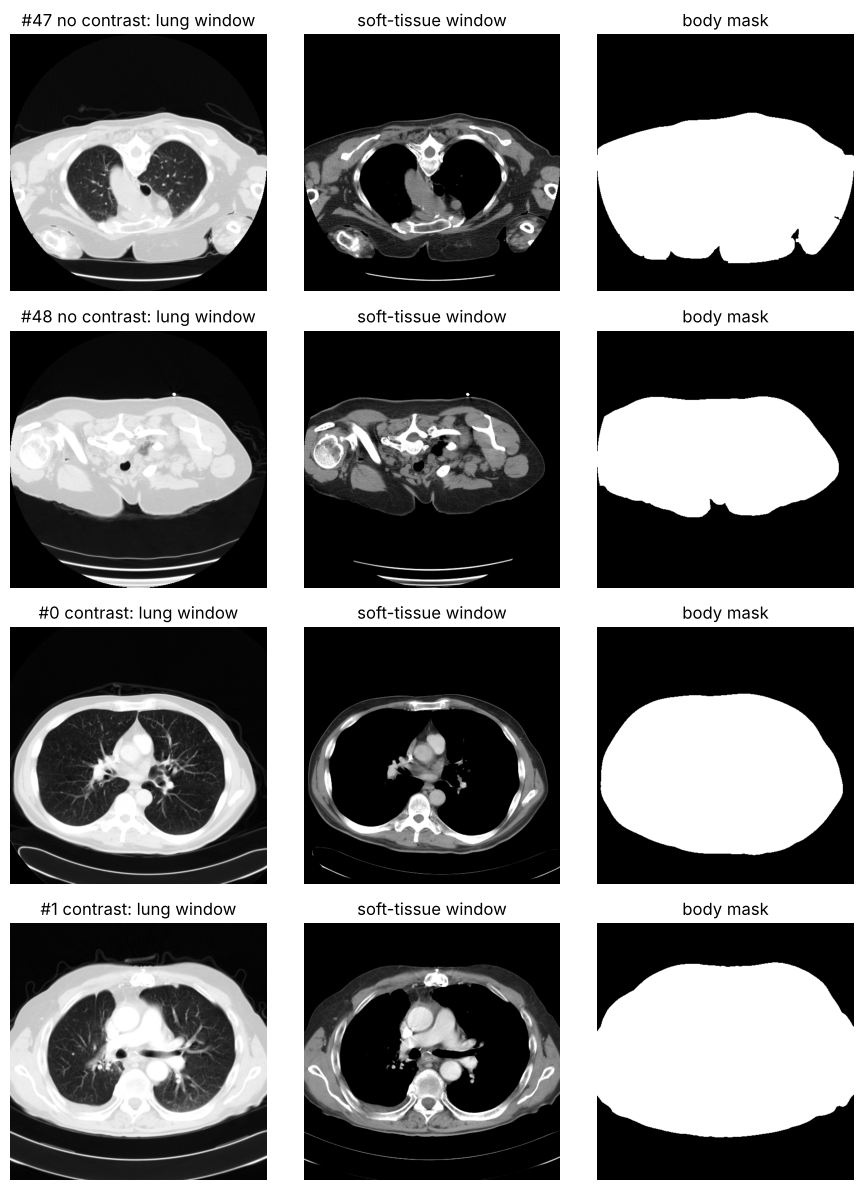

In [20]:
# Visual check of preprocessing on 2 slices per class: lung window, soft-tissue window, body mask
idx = list(np.where(y == 0)[0][:2]) + list(np.where(y == 1)[0][:2])
fig, ax = plt.subplots(len(idx), 3, figsize=(9, 3 * len(idx)))
for r, i in enumerate(idx):
    lab = 'contrast' if y[i] else 'no contrast'
    ax[r, 0].imshow(window(HU[i], -600, 1500), cmap='gray'); ax[r, 0].set_title(f'#{i} {lab}: lung window')
    ax[r, 1].imshow(window(HU[i], 40, 400), cmap='gray'); ax[r, 1].set_title('soft-tissue window')
    ax[r, 2].imshow(MASK[i], cmap='gray'); ax[r, 2].set_title('body mask')
for a in ax.ravel(): a.axis('off'); a.grid(False)
savefig('01_preprocessing_examples')

## Part 4 — Image features grounded in CT physics

**Why these features?** Iodinated contrast raises the HU of blood from about 40 HU to roughly 150–400 HU, so the aorta, heart chambers and vessels light up. A model should therefore look at *how much tissue inside the body falls in the enhanced-blood HU band*. All features are computed **inside the body mask only**.

| Group | Features |
|---|---|
| HU tissue fractions | share of body pixels that are air/lung (< −400), fat (−190…−30), soft tissue (−30…130), enhanced (130…400), dense/bone (> 400) |
| **Contrast Enhancement Index (CEI)** | enhanced ÷ (soft + enhanced) — our engineered feature |
| Enhanced-region shape | size of the largest connected enhanced region (aorta/heart are large blobs) and number of enhanced regions |
| HU distribution of non-air tissue (−200…400) | mean, SD, 5/25/50/75/90/95th percentiles, skewness, kurtosis |
| Texture | GLCM contrast, homogeneity, energy, correlation, dissimilarity on the soft-tissue window; mean edge strength (Sobel) |
| Body size | body-mask area (partly patient size, partly field of view) |

**Known overlap:** trabecular bone (≈ 200–600 HU) partly overlaps the enhanced-blood band. The shape features and the model weights help, but this is a real limitation — mention it.

In [21]:
BANDS = {'air_lung': (-1025, -400), 'fat': (-190, -30), 'soft': (-30, 130), 'enhanced': (130, 400), 'dense': (400, 3072)}

def image_features(hu, m):
    v = hu[m]; f = {}
    f['body_area_frac'] = m.mean()
    for k, (lo, hi) in BANDS.items():
        f[f'frac_{k}'] = ((v >= lo) & (v < hi)).mean()
    f['CEI'] = f['frac_enhanced'] / (f['frac_soft'] + f['frac_enhanced'] + 1e-6)

    enh = (((hu >= 130) & (hu < 400)) & m).astype(np.uint8)
    enh = cv2.morphologyEx(enh, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))    # remove speckle noise
    n, _, st, _ = cv2.connectedComponentsWithStats(enh)
    areas = st[1:, cv2.CC_STAT_AREA] if n > 1 else np.array([0])
    f['enh_largest_blob_frac'] = areas.max() / m.sum()
    f['enh_n_blobs_gt50px'] = int((areas > 50).sum())

    t = v[(v > -200) & (v < 400)]
    t = t if t.size > 50 else np.array([0.0, 0.0])
    f.update({'tis_mean': t.mean(), 'tis_std': t.std(), 'tis_skew': stats.skew(t), 'tis_kurt': stats.kurtosis(t)})
    for q in (5, 25, 50, 75, 90, 95):
        f[f'tis_p{q}'] = np.percentile(t, q)

    w = window(hu, 40, 400)
    g = np.maximum(cv2.resize(w, (256, 256), interpolation=cv2.INTER_AREA) // 8, 1)           # grey levels 1..31 inside body
    g[cv2.resize(m.astype(np.uint8), (256, 256), interpolation=cv2.INTER_NEAREST) == 0] = 0   # level 0 = background
    glcm = graycomatrix(g, distances=[1, 2], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4], levels=32, symmetric=True).astype(float)
    glcm[0, :] = 0; glcm[:, 0] = 0                                                            # ignore background pairs
    glcm /= glcm.sum(axis=(0, 1), keepdims=True) + 1e-12
    for p in ('contrast', 'homogeneity', 'energy', 'correlation', 'dissimilarity'):
        f[f'glcm_{p}'] = graycoprops(glcm, p).mean()
    wf = w.astype(np.float32)
    f['edge_mean'] = np.hypot(cv2.Sobel(wf, cv2.CV_32F, 1, 0), cv2.Sobel(wf, cv2.CV_32F, 0, 1))[m].mean()
    return f

t0 = time.time()
X_img = pd.DataFrame([image_features(h, m) for h, m in zip(HU, MASK)])
const = X_img.columns[X_img.nunique() <= 1]
if len(const): print('Dropping constant features:', list(const))
X_img = X_img.drop(columns=const)
print(f'{X_img.shape[1]} image features for {len(X_img)} slices in {time.time() - t0:.1f}s')
display(X_img.describe().T.round(3))

25 image features for 94 slices in 2.8s


,count,mean,std,min,25%,50%,75%,max
body_area_frac,94.0,0.500,0.156,0.182,0.386,0.518,0.603,0.834
frac_air_lung,94.0,0.221,0.170,0.002,0.029,0.218,0.368,0.498
frac_fat,94.0,0.280,0.128,0.030,0.183,0.270,0.359,0.664
frac_soft,94.0,0.385,0.145,0.175,0.268,0.353,0.469,0.787
frac_enhanced,94.0,0.076,0.041,0.017,0.043,0.063,0.104,0.205
frac_dense,94.0,0.017,0.012,0.001,0.009,0.013,0.024,0.053
CEI,94.0,0.173,0.091,0.037,0.107,0.146,0.255,0.403
enh_largest_blob_frac,94.0,0.019,0.018,0.000,0.009,0.014,0.024,0.116
enh_n_blobs_gt50px,94.0,16.043,9.508,0.000,7.000,16.000,22.000,39.000
tis_mean,94.0,11.476,31.103,-47.486,-11.887,9.826,30.393,104.729


## Part 5 — Patient metadata

Kept: **age** (CSV) and **sex** (DICOM `PatientSex`, if present). These are genuine patient attributes known before the scan. Everything flagged in Part 2 is excluded.

*Sensitivity analysis (optional, Part 7.4):* scanner/acquisition settings (e.g. kVp, slice thickness) are **not patient metadata** and can act as shortcuts (contrast studies often follow a different protocol). They are tested separately and never mixed into the main comparison.

In [22]:
X_meta = pd.DataFrame(index=df.index)
if age_col: X_meta['age'] = pd.to_numeric(df[age_col], errors='coerce')
if 'PatientSex' in hdr:
    X_meta['sex_male'] = hdr['PatientSex'].str.upper().map({'M': 1, 'F': 0})        # anything else -> NaN -> imputed
X_meta = X_meta.loc[:, X_meta.notna().any()]
assert age_col not in LEAKY and 'dcm_PatientSex' not in LEAKY, 'a metadata field was flagged as leaky in Part 2'
print('Metadata features:', list(X_meta.columns)); display(X_meta.describe().round(2))

# Acquisition tags for the sensitivity analysis only: numeric, present in >=90% of files, not leaky, not constant
ACQ_CANDIDATES = ['KVP', 'SliceThickness', 'XRayTubeCurrent', 'Exposure', 'ExposureTime', 'PixelSpacing', 'DataCollectionDiameter']
X_acq = pd.DataFrame({t: pd.to_numeric(hdr[t].str.split(',').str[0].str.strip('[] '), errors='coerce')
                      for t in ACQ_CANDIDATES if t in hdr and f'dcm_{t}' not in LEAKY})
X_acq = X_acq.loc[:, (X_acq.notna().mean() >= .9) & (X_acq.nunique() > 1)]
# ...plus categorical scanner/protocol tags (one-hot). Free-text descriptions are excluded: they can state the answer (Part 2).
ACQ_CATEGORICAL = ['BodyPartExamined', 'Manufacturer', 'ManufacturerModelName', 'ConvolutionKernel', 'PatientPosition', 'FilterType']
acq_cat = [t for t in ACQ_CATEGORICAL if t in hdr and f'dcm_{t}' not in LEAKY and hdr[t].notna().mean() >= .8 and 1 < hdr[t].nunique() <= 25]
if acq_cat:
    X_acq = pd.concat([X_acq, pd.get_dummies(hdr[acq_cat].fillna('missing'), dtype=float)], axis=1)
print('Acquisition features (sensitivity analysis only):', [c for c in X_acq.columns if '_' not in c] + acq_cat)

Metadata features: ['age', 'sex_male']


,age,sex_male
count,94.00,94.00
mean,67.47,0.53
std,9.34,0.50
min,39.00,0.00
25%,61.00,0.00
50%,70.00,1.00
75%,74.00,1.00
max,83.00,1.00


Acquisition features (sensitivity analysis only): ['KVP', 'SliceThickness', 'XRayTubeCurrent', 'Exposure', 'ExposureTime', 'BodyPartExamined', 'Manufacturer', 'ManufacturerModelName', 'ConvolutionKernel', 'PatientPosition', 'FilterType']


### 5b — Missing values, outliers, encoding, scaling, class balance

| Issue | Check | Decision and reason |
|---|---|---|
| Missing values | count per feature below | Median imputation **inside each training fold** (fitting it on all data would leak test statistics). |
| Outliers | count values beyond 3×IQR | **Kept.** In CT, extreme values are usually real anatomy (large patient, metal, dense bone), not entry errors; Random Forest is insensitive to them and the other models see standardised features. Removing them would also remove exactly the unusual patients a tool must handle. |
| Encoding | sex → 1 (M) / 0 (F); anything else → missing | Only one categorical field; binary encoding is enough. |
| Normalisation | `StandardScaler` | Inside the pipeline, fitted on training folds only. Needed for LogReg/SVM, harmless for RF. |
| Class imbalance | ratio below | Stratified folds + `class_weight='balanced'`; balanced accuracy is reported alongside accuracy. |
| Train/test split | — | Repeated patient-level cross-validation (Part 7) instead of a single split. |

In [23]:
feats = pd.concat([X_img, X_meta], axis=1)
miss = feats.isna().sum()
print('Missing values:', 'none' if miss.sum() == 0 else miss[miss > 0].to_dict())
q1, q3 = X_img.quantile(.25), X_img.quantile(.75); iqr = q3 - q1
outl = ((X_img < q1 - 3 * iqr) | (X_img > q3 + 3 * iqr)).sum()
print('\nFeatures with values beyond 3×IQR (kept, see table above):')
print(outl[outl > 0].sort_values(ascending=False).to_string() if outl.any() else '  none')
counts = np.bincount(y, minlength=2)
print(f'\nClass balance: {counts[0]} no-contrast vs {counts[1]} contrast (minority share {counts.min() / counts.sum():.0%})')

Missing values: none

Features with values beyond 3×IQR (kept, see table above):
tis_p75                  3
enh_largest_blob_frac    2
tis_p5                   1
glcm_contrast            1
edge_mean                1

Class balance: 47 no-contrast vs 47 contrast (minority share 50%)


## Part 6 — Exploratory visualisation

Questions we ask the data before modelling: Is the dataset balanced? Does age differ by contrast status (if yes, age alone might "predict" contrast through hospital practice, not biology)? Do the HU histograms differ where physics says they should (130–400 HU)?

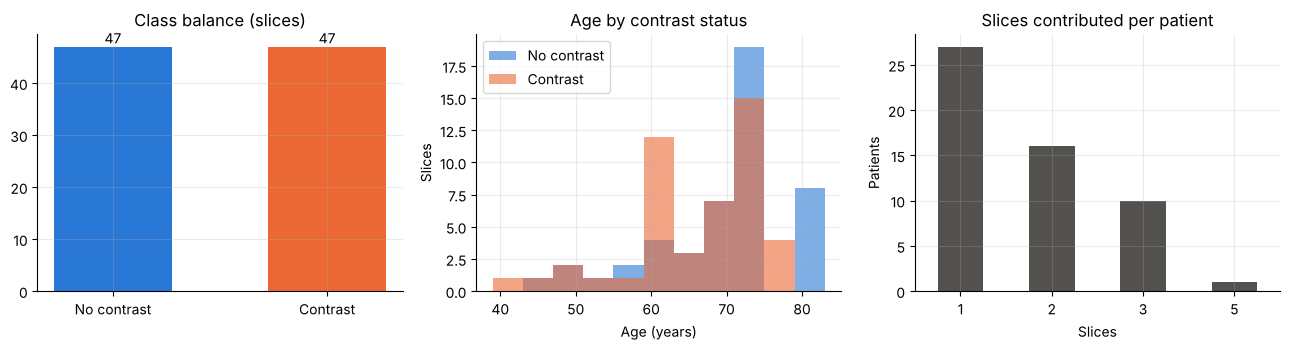

Age: median 71 (no contrast) vs 69 (contrast); Mann-Whitney p = 0.104


In [24]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
cnt = pd.Series(y).value_counts().sort_index()
ax[0].bar(['No contrast', 'Contrast'], cnt.values, color=[C_NO, C_YES], width=.55)
for i, v in enumerate(cnt.values): ax[0].text(i, v, str(v), ha='center', va='bottom')
ax[0].set_title('Class balance (slices)')
if 'age' in X_meta:
    bins = np.linspace(X_meta.age.min(), X_meta.age.max(), 12)
    ax[1].hist(X_meta.age[y == 0], bins, alpha=.6, color=C_NO, label='No contrast')
    ax[1].hist(X_meta.age[y == 1], bins, alpha=.6, color=C_YES, label='Contrast')
    ax[1].set(title='Age by contrast status', xlabel='Age (years)', ylabel='Slices'); ax[1].legend()
if PID_COL:
    pd.Series(groups).value_counts().value_counts().sort_index().plot.bar(ax=ax[2], color='#52514e', rot=0)
    ax[2].set(title='Slices contributed per patient', xlabel='Slices', ylabel='Patients')
else: ax[2].axis('off')
savefig('02_class_age_patients')
if 'age' in X_meta:
    u = stats.mannwhitneyu(X_meta.age[y == 0].dropna(), X_meta.age[y == 1].dropna())
    print(f'Age: median {X_meta.age[y==0].median():.0f} (no contrast) vs {X_meta.age[y==1].median():.0f} (contrast); Mann-Whitney p = {u.pvalue:.3f}')

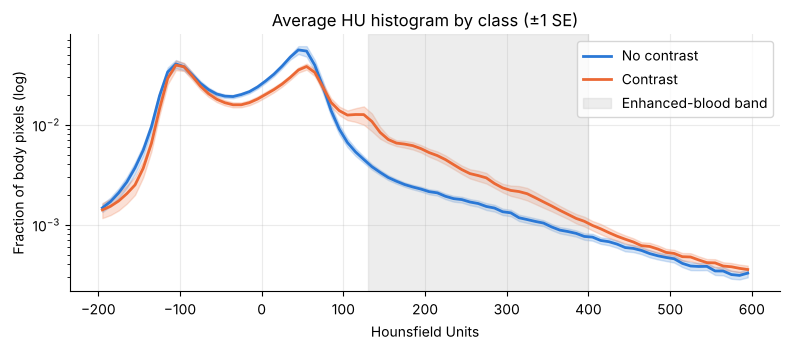

In [25]:
# Mean HU histogram inside the body, per class (shaded band = enhanced-blood range)
edges = np.arange(-200, 601, 10); mids = (edges[:-1] + edges[1:]) / 2
H = np.stack([np.histogram(h[m], edges)[0] / m.sum() for h, m in zip(HU, MASK)])
plt.figure(figsize=(8, 3.6))
for cls, c, lab in [(0, C_NO, 'No contrast'), (1, C_YES, 'Contrast')]:
    mu, sd = H[y == cls].mean(0), H[y == cls].std(0) / np.sqrt((y == cls).sum())
    plt.plot(mids, mu, color=c, lw=2, label=lab); plt.fill_between(mids, mu - sd, mu + sd, color=c, alpha=.2)
plt.axvspan(130, 400, color='#bbbbbb', alpha=.25, label='Enhanced-blood band')
plt.yscale('log'); plt.xlabel('Hounsfield Units'); plt.ylabel('Fraction of body pixels (log)')
plt.title('Average HU histogram by class (±1 SE)'); plt.legend()
savefig('03_hu_histograms')

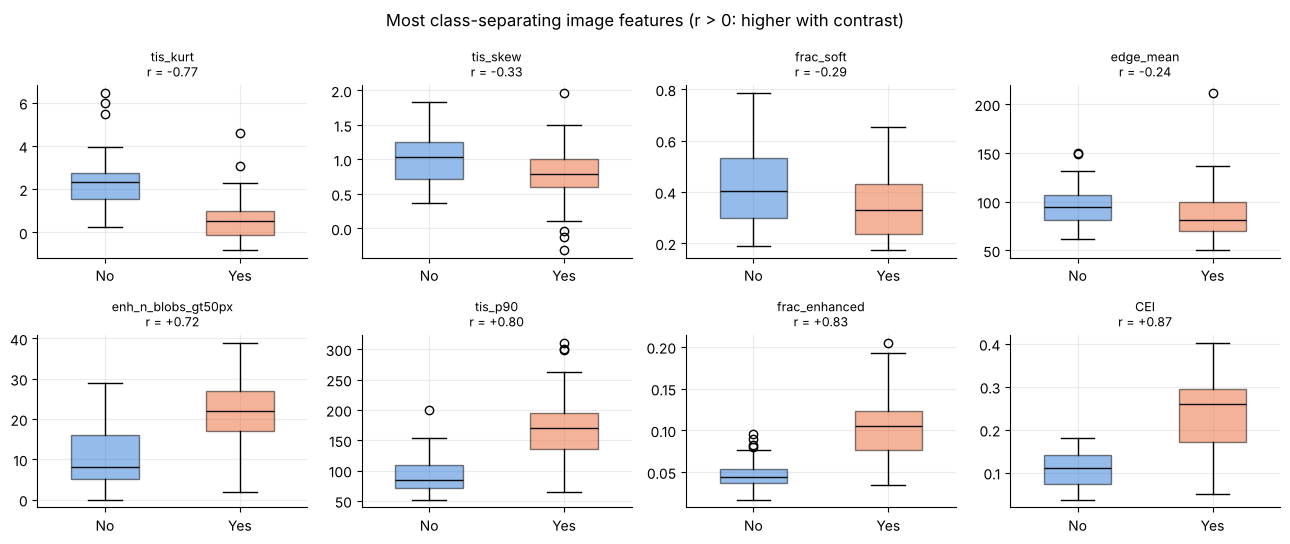

In [26]:
# Which image features differ most between classes? (effect size = rank-biserial correlation, model-free)
def rank_biserial(a, b):
    U = stats.mannwhitneyu(a, b).statistic
    return 2 * U / (len(a) * len(b)) - 1
eff = pd.Series({c: rank_biserial(X_img[c][y == 1], X_img[c][y == 0]) for c in X_img}).sort_values()
top = pd.concat([eff.head(4), eff.tail(4)]).index
fig, ax = plt.subplots(2, 4, figsize=(13, 5.5))
for a, c in zip(ax.ravel(), top):
    bp = a.boxplot([X_img[c][y == 0], X_img[c][y == 1]], widths=.5, patch_artist=True); a.set_xticks([1, 2], ['No', 'Yes'])
    for patch, col in zip(bp['boxes'], [C_NO, C_YES]): patch.set_facecolor(col); patch.set_alpha(.5)
    for med in bp['medians']: med.set_color('#0b0b0b')
    a.set_title(f'{c}\nr = {eff[c]:+.2f}', fontsize=9)
fig.suptitle('Most class-separating image features (r > 0: higher with contrast)')
savefig('04_feature_boxplots')

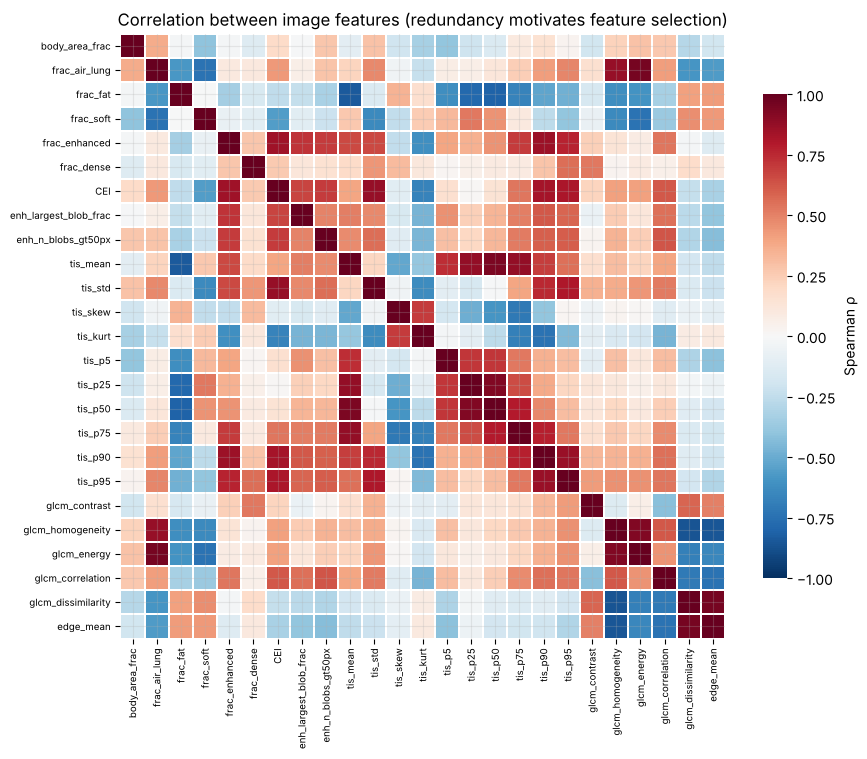

In [27]:
corr = X_img.corr(method='spearman')
plt.figure(figsize=(9, 7.5))
sns.heatmap(corr, cmap='RdBu_r', vmin=-1, vmax=1, center=0, square=True, xticklabels=True, yticklabels=True,
            cbar_kws={'label': 'Spearman ρ', 'shrink': .8}, linewidths=.3, linecolor='white')
plt.xticks(fontsize=7); plt.yticks(fontsize=7); plt.title('Correlation between image features (redundancy motivates feature selection)')
savefig('05_feature_correlation')

## Part 7 — Models and patient-level evaluation

**Splitting.** If a patient has several slices, a normal random split could put one slice in training and another in testing — the model would recognise the *patient*, not the contrast. `StratifiedGroupKFold` keeps every patient's slices in the same fold and keeps class balance similar across folds.

**Why repeated CV, not one train/test split?** With ~100 slices, a single 80/20 split leaves ~20 test slices, and the score swings a lot depending on which 20. We repeat 5-fold CV 10 times with different shuffles and report mean ± SD.

**Models.** Logistic Regression (simple, interpretable), Random Forest (non-linear, robust to scaling), RBF-SVM. Scaling and imputation sit *inside* the pipeline, so they are fitted on training folds only (another leakage guard).

**Metrics.** Precision, recall (sensitivity), specificity, F1, accuracy, balanced accuracy, ROC-AUC, and a confusion matrix from out-of-fold predictions.

In [28]:
def make_models():
    pre = [('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]
    return {'LogReg': Pipeline(pre + [('clf', LogisticRegression(max_iter=5000, class_weight='balanced'))]),
            'RandomForest': Pipeline(pre[:1] + [('clf', RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight='balanced', random_state=SEED))]),
            # SVMs output distances, not probabilities; sigmoid calibration (fitted on the training fold only) converts them
            'SVM-RBF': Pipeline(pre + [('clf', CalibratedClassifierCV(SVC(kernel='rbf', class_weight='balanced'), method='sigmoid', cv=3, ensemble=False))])}

def cv_splits(X, y, groups, repeats=N_REPEATS, n_splits=N_SPLITS):
    n_splits = min(n_splits, len(np.unique(groups)), np.bincount(y).min())
    for r in range(repeats):
        cv = StratifiedGroupKFold(n_splits, shuffle=True, random_state=SEED + r)
        for k, (tr, te) in enumerate(cv.split(X, y, groups)):
            yield r, k, tr, te

def scores(y_true, prob, thr=.5):
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {'AUC': roc_auc_score(y_true, prob) if len(set(y_true)) == 2 else np.nan,
            'Accuracy': accuracy_score(y_true, pred), 'BalancedAcc': balanced_accuracy_score(y_true, pred),
            'Precision': precision_score(y_true, pred, zero_division=0), 'Recall': recall_score(y_true, pred, zero_division=0),
            'Specificity': tn / (tn + fp) if tn + fp else np.nan, 'F1': f1_score(y_true, pred, zero_division=0)}

def evaluate(model, X, y, groups, repeats=N_REPEATS):
    rows, oof = [], np.zeros((repeats, len(y)))
    for r, k, tr, te in cv_splits(X, y, groups, repeats):
        m = clone(model).fit(X.iloc[tr], y[tr])
        p = m.predict_proba(X.iloc[te])[:, 1]; oof[r, te] = p
        rows.append({'repeat': r, 'fold': k, **scores(y[te], p)})
    return pd.DataFrame(rows), oof.mean(0)     # per-fold scores, out-of-fold probability averaged over repeats

In [29]:
FEATURE_SETS = {'Metadata only': X_meta, 'Image only': X_img, 'Image + Metadata': pd.concat([X_img, X_meta], axis=1)}
fold_scores, oof_prob = {}, {}
t0 = time.time()
for fs, X in FEATURE_SETS.items():
    if X.shape[1] == 0: print(f'skip {fs}: no features'); continue
    for mn, model in make_models().items():
        fold_scores[(fs, mn)], oof_prob[(fs, mn)] = evaluate(model, X, y, groups)
print(f'done in {time.time() - t0:.0f}s')

METRICS = ['AUC', 'BalancedAcc', 'Precision', 'Recall', 'Specificity', 'F1', 'Accuracy']
summary = pd.concat({k: v[METRICS].agg(['mean', 'std']).T for k, v in fold_scores.items()}, axis=0)
summary = summary['mean'].round(3).astype(str) + ' ± ' + summary['std'].round(3).astype(str)
summary = summary.unstack()[METRICS]
summary.index.names = ['Feature set', 'Model']
summary.to_csv(OUT / 'baseline_cv_summary.csv'); display(summary)

done in 77s


AUC    BalancedAcc      Precision  \
Feature set      Model                                                       
Image + Metadata LogReg        0.926 ± 0.054  0.872 ± 0.072  0.908 ± 0.087   
                 RandomForest  0.937 ± 0.056  0.874 ± 0.071   0.92 ± 0.091   
                 SVM-RBF       0.932 ± 0.062  0.868 ± 0.088  0.934 ± 0.096   
Image only       LogReg        0.938 ± 0.053  0.894 ± 0.064  0.939 ± 0.076   
                 RandomForest  0.937 ± 0.056  0.873 ± 0.064   0.921 ± 0.09   
                 SVM-RBF       0.937 ± 0.053  0.866 ± 0.077  0.943 ± 0.082   
Metadata only    LogReg        0.534 ± 0.138  0.526 ± 0.124  0.535 ± 0.195   
                 RandomForest  0.554 ± 0.137  0.533 ± 0.112  0.525 ± 0.106   
                 SVM-RBF        0.464 ± 0.13   0.468 ± 0.11  0.464 ± 0.219   

                                      Recall    Specificity             F1  \
Feature set      Model                                                       
Image + Metadata LogReg         0.836 ± 0.13  0.908 ± 0.092  0.862 ± 0.086   
                 RandomForest   0.833 ± 0.13    0.915 ± 0.1  0.865 ± 0.084   
                 SVM-RBF       0.798 ± 0.136  0.939 ± 0.092  0.854 ± 0.103   
Image only       LogReg        0.848 ± 0.117   0.939 ± 0.08  0.885 ± 0.074   
                 RandomForest  0.832 ± 0.128    0.915 ± 0.1  0.864 ± 0.076   
                 SVM-RBF       0.783 ± 0.128  0.949 ± 0.076  0.849 ± 0.094   
Metadata only    LogReg        0.467 ± 0.207  0.584 ± 0.232  0.477 ± 0.173   
                 RandomForest  0.623 ± 0.216  0.444 ± 0.196  0.556 ± 0.147   
                 SVM-RBF       0.484 ± 0.324  0.451 ± 0.325  0.426 ± 0.206   

                                    Accuracy  
Feature set      Model                        
Image + Metadata LogReg        0.871 ± 0.073  
                 RandomForest  0.874 ± 0.071  
                 SVM-RBF       0.868 ± 0.088  
Image only       LogReg        0.893 ± 0.064  
                 RandomForest  0.873 ± 0.064  
                 SVM-RBF       0.866 ± 0.078  
Metadata only    LogReg        0.525 ± 0.124  
                 RandomForest  0.532 ± 0.113  
                 SVM-RBF       0.464 ± 0.111

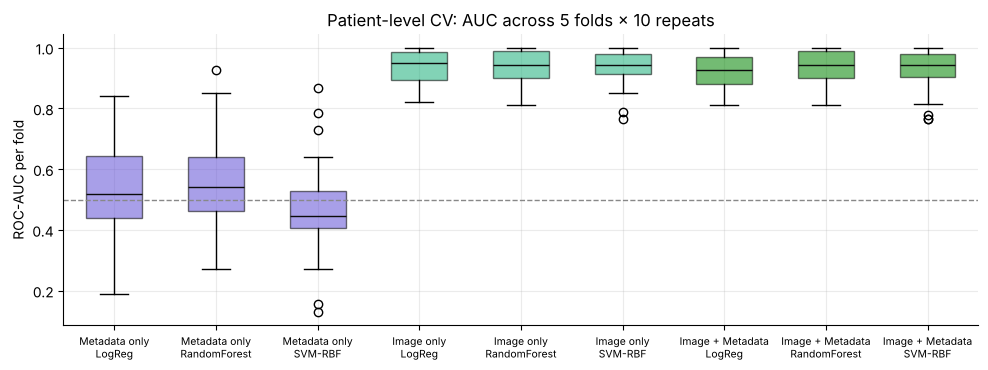

In [30]:
# AUC distribution across the 50 folds — shows how stable each result is
keys = list(fold_scores)
plt.figure(figsize=(10, 3.8))
bp = plt.boxplot([fold_scores[k]['AUC'].dropna() for k in keys], widths=.55, patch_artist=True)
for patch, k in zip(bp['boxes'], keys): patch.set_facecolor(C_SET[k[0]]); patch.set_alpha(.55)
for med in bp['medians']: med.set_color('#0b0b0b')
plt.xticks(range(1, len(keys) + 1), [f'{fs}\n{mn}' for fs, mn in keys], fontsize=7.5)
plt.axhline(.5, ls='--', color='#888', lw=1); plt.ylabel('ROC-AUC per fold'); plt.title('Patient-level CV: AUC across 5 folds × 10 repeats')
savefig('06_auc_boxplots')

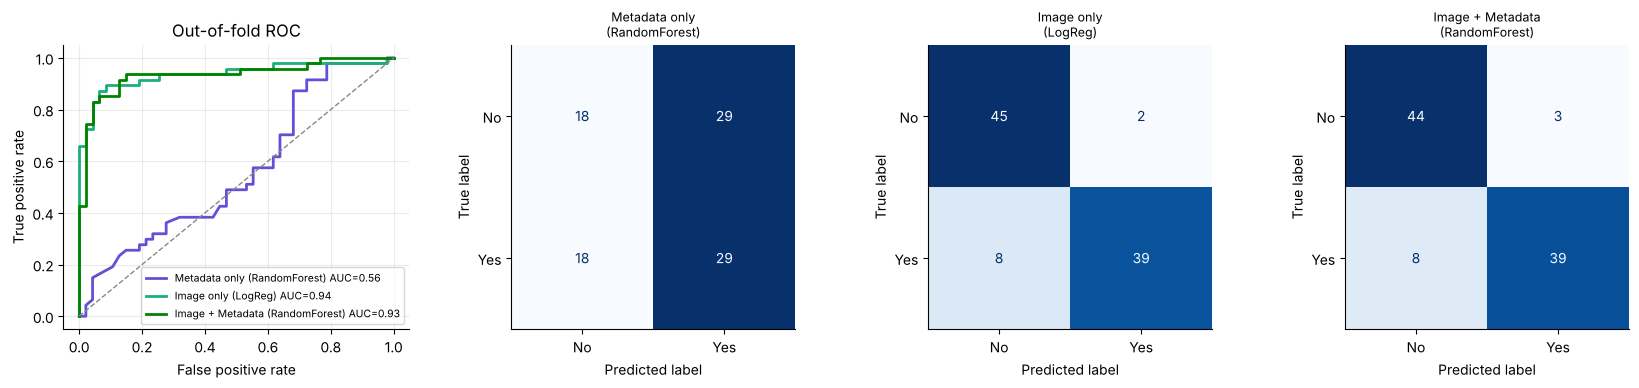

In [31]:
# ROC curves (out-of-fold) — best model of each feature set, chosen by mean CV AUC
best = {fs: max([k for k in fold_scores if k[0] == fs], key=lambda k: fold_scores[k]['AUC'].mean()) for fs in FEATURE_SETS if any(k[0] == fs for k in fold_scores)}
fig, ax = plt.subplots(1, 1 + len(best), figsize=(4.2 * (1 + len(best)), 3.9))
for fs, k in best.items():
    fpr, tpr, _ = roc_curve(y, oof_prob[k])
    ax[0].plot(fpr, tpr, lw=2, color=C_SET[fs], label=f'{fs} ({k[1]}) AUC={roc_auc_score(y, oof_prob[k]):.2f}')
ax[0].plot([0, 1], [0, 1], '--', color='#888', lw=1); ax[0].set(xlabel='False positive rate', ylabel='True positive rate', title='Out-of-fold ROC'); ax[0].legend(fontsize=7.5, loc='lower right')
for a, (fs, k) in zip(ax[1:], best.items()):
    ConfusionMatrixDisplay(confusion_matrix(y, (oof_prob[k] >= .5).astype(int)), display_labels=['No', 'Yes']).plot(ax=a, cmap='Blues', colorbar=False)
    a.set_title(f'{fs}\n({k[1]})', fontsize=9); a.grid(False)
savefig('07_roc_confusion')

In [32]:
# Paired comparison on identical folds: how often does adding metadata beat image-only?
def paired(a, b):
    d = fold_scores[a]['AUC'].values - fold_scores[b]['AUC'].values
    return f'mean ΔAUC = {np.nanmean(d):+.3f}, better in {np.mean(d > 0):.0%} of folds, worse in {np.mean(d < 0):.0%}'
for mn in make_models():
    if ('Image + Metadata', mn) in fold_scores and ('Image only', mn) in fold_scores:
        print(f'{mn:13s} combined vs image-only: ', paired(('Image + Metadata', mn), ('Image only', mn)))
print('(Folds overlap, so these are descriptive comparisons, not independent significance tests.)')

LogReg        combined vs image-only:  mean ΔAUC = -0.013, better in 6% of folds, worse in 48%
RandomForest  combined vs image-only:  mean ΔAUC = +0.000, better in 22% of folds, worse in 24%
SVM-RBF       combined vs image-only:  mean ΔAUC = -0.005, better in 12% of folds, worse in 36%
(Folds overlap, so these are descriptive comparisons, not independent significance tests.)


### 7.4 Sensitivity analysis — do scanner settings act as a shortcut?

Not part of the main comparison. If acquisition settings alone predict contrast well, a model could learn *protocol* instead of *anatomy*; that is a classic shortcut-learning risk worth discussing.

In [33]:
if X_acq.shape[1]:
    acq_scores, _ = evaluate(make_models()['RandomForest'], X_acq, y, groups)
    print('Acquisition-only RandomForest AUC: %.3f ± %.3f' % (acq_scores.AUC.mean(), acq_scores.AUC.std()))
    for t in acq_cat[:3]:                                    # how lopsided are the main scanner categories between classes?
        display(pd.crosstab(hdr[t].fillna('missing').rename(t), pd.Series(y, name='label (1 = contrast)')))
else:
    print('No usable acquisition tags found — skipped.')

Acquisition-only RandomForest AUC: 0.730 ± 0.122


label (1 = contrast),0,1
BodyPartExamined,,
CHEST,15,29
LUNG,32,18


label (1 = contrast),0,1
Manufacturer,,
GE MEDICAL SYSTEMS,23,10
SIEMENS,24,37


label (1 = contrast),0,1
ManufacturerModelName,,
Biograph 40,2,0
Biograph 6,2,0
Definition AS+,0,1
Discovery ST,2,1
Discovery STE,3,1
Emotion,2,2
Emotion Duo,6,0
HiSpeed CT/i,5,0
LightSpeed Plus,0,1


## Part 8 — Improvement, robustness and explainability

**8.1 Nested tuning + feature selection.** The image set has ~30 correlated features for ~100 slices, which invites overfitting. We tune `k` (how many features `SelectKBest` keeps) and the model's regularisation **inside** each training fold (inner grouped 3-fold CV), and score on the untouched outer fold. Tuning on the same folds you report would leak test information into model choice — nested CV avoids that.

In [34]:
X_comb = FEATURE_SETS['Image + Metadata']
def f_score(X, y):   # ANOVA F-score; a feature that is constant within a fold gets score 0 instead of a divide-by-zero warning
    with np.errstate(divide='ignore', invalid='ignore'):
        F, p = f_classif(X, y)
    return np.nan_to_num(F, nan=0.0, posinf=1e12), np.nan_to_num(p, nan=1.0)

def tuned(name):
    n_feat = X_comb.shape[1]
    ks = sorted({k for k in (3, 5, 8, 12) if k < n_feat} | {'all'}, key=lambda k: n_feat if k == 'all' else k)
    pre = [('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler()), ('select', SelectKBest(f_score))]
    if name == 'LogReg':
        pipe = Pipeline(pre + [('clf', LogisticRegression(max_iter=5000, class_weight='balanced'))])
        grid = {'select__k': ks, 'clf__C': [0.01, 0.1, 1, 10]}
    else:
        pipe = Pipeline(pre + [('clf', RandomForestClassifier(n_estimators=100, min_samples_leaf=2, class_weight='balanced', random_state=SEED))])
        grid = {'select__k': ks, 'clf__max_depth': [3, None]}
    return pipe, grid

NESTED_REPEATS = 3          # fewer repeats than Part 7: nested CV costs ~25x more fits
nested, chosen, nested_oof = {}, {}, {}
t0 = time.time()
for name in ('LogReg', 'RandomForest'):
    pipe, grid = tuned(name); rows, picks, oof = [], [], np.zeros((NESTED_REPEATS, len(y)))
    for r, k, tr, te in cv_splits(X_comb, y, groups, NESTED_REPEATS):
        inner = StratifiedGroupKFold(min(3, len(np.unique(groups[tr]))), shuffle=True, random_state=SEED)
        gs = GridSearchCV(pipe, grid, scoring='roc_auc', cv=inner, n_jobs=-1).fit(X_comb.iloc[tr], y[tr], groups=groups[tr])
        p = gs.predict_proba(X_comb.iloc[te])[:, 1]; oof[r, te] = p
        rows.append(scores(y[te], p)); picks.append(gs.best_params_)
    nested[name], chosen[name], nested_oof[name] = pd.DataFrame(rows), pd.DataFrame(picks), oof.mean(0)
print(f'done in {time.time() - t0:.0f}s')

cmp = []
for name in nested:
    base = fold_scores[('Image + Metadata', name)]
    cmp.append({'Model': name, 'Baseline AUC': f"{base.AUC.mean():.3f} ± {base.AUC.std():.3f}",
                'Nested-tuned AUC': f"{nested[name].AUC.mean():.3f} ± {nested[name].AUC.std():.3f}",
                'Baseline F1': f"{base.F1.mean():.3f}", 'Tuned F1': f"{nested[name].F1.mean():.3f}"})
cmp = pd.DataFrame(cmp); cmp.to_csv(OUT / 'nested_tuning_comparison.csv', index=False); display(cmp)
for name in chosen:
    print(f'\n{name}: hyper-parameters chosen across outer folds'); display(chosen[name].astype(str).value_counts().head(5))

done in 48s


,Model,Baseline AUC,Nested-tuned AUC,Baseline F1,Tuned F1
0,LogReg,0.926 ± 0.054,0.922 ± 0.059,0.862,0.834
1,RandomForest,0.937 ± 0.056,0.921 ± 0.067,0.865,0.860



LogReg: hyper-parameters chosen across outer folds


clf__C  select__k
10.0    3            2
0.01    3            2
        8            2
0.1     all          2
10.0    5            1
Name: count, dtype: int64


RandomForest: hyper-parameters chosen across outer folds


clf__max_depth  select__k
3.0             3            3
                8            3
                all          2
                12           1
Name: count, dtype: int64

**Reading this honestly:** if the tuned model is *not* better, that is a valid finding — it means the default model was already near what this small dataset supports. Report whichever happened.

**8.2 Is the score better than chance?** A label-permutation test: shuffle the labels, re-run exactly the same patient-grouped CV, repeat 200 times. The p-value is the share of shuffled runs that score at least as well as the real labels. If every patient had one label we would shuffle whole patients; in this dataset some patients have slices of both classes (Part 1.7), so the code shuffles slice labels while the folds stay patient-grouped.

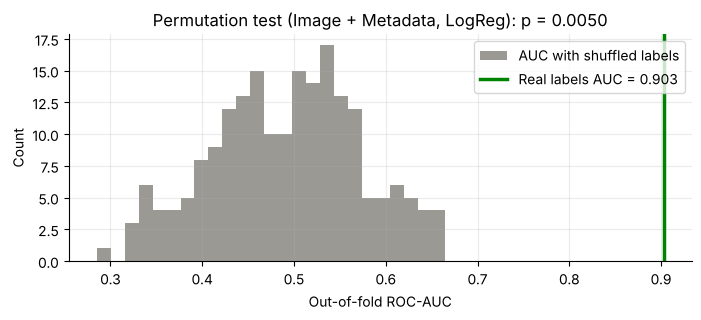

In [35]:
def cv_auc(model, X, y_vec, splits):
    p = np.zeros(len(y_vec))
    for tr, te in splits:
        p[te] = clone(model).fit(X.iloc[tr], y_vec[tr]).predict_proba(X.iloc[te])[:, 1]
    return roc_auc_score(y_vec, p)

def patient_shuffle(y_vec, groups, rng):
    pts = pd.Series(y_vec).groupby(groups).agg(lambda s: s.mode()[0])
    if (pd.Series(y_vec).groupby(groups).nunique() > 1).any():
        return rng.permutation(y_vec)                       # some patients have both labels -> shuffle slices (folds stay patient-grouped)
    mapping = dict(zip(pts.index, rng.permutation(pts.values)))
    return np.array([mapping[g] for g in groups])

N_PERM = 200
perm_model = make_models()['LogReg']
splits = [(tr, te) for _, _, tr, te in cv_splits(X_comb, y, groups, repeats=1)]
real = cv_auc(perm_model, X_comb, y, splits)
rng = np.random.default_rng(SEED)
null = np.array([cv_auc(perm_model, X_comb, patient_shuffle(y, groups, rng), splits) for _ in range(N_PERM)])
p_val = (1 + (null >= real).sum()) / (1 + N_PERM)
plt.figure(figsize=(7, 3.3))
plt.hist(null, 25, color='#9a9994', label='AUC with shuffled labels'); plt.axvline(real, color=C_SET['Image + Metadata'], lw=2.5, label=f'Real labels AUC = {real:.3f}')
plt.xlabel('Out-of-fold ROC-AUC'); plt.ylabel('Count'); plt.title(f'Permutation test (Image + Metadata, LogReg): p = {p_val:.4f}'); plt.legend()
savefig('08_permutation_test')

**8.3 Explainability — which features drive the predictions?** Permutation importance measures how much held-out AUC drops when a feature is shuffled. We compute it on the **test fold** of each patient-level split (not on training data, which would overstate importance), then average.

Many of our features are correlated (e.g. `frac_enhanced`, `CEI`, `tis_p95` all rise with contrast). Shuffling one of them barely hurts, because its twins still carry the information — so single-feature importance *understates* them. We therefore also shuffle **whole feature groups** together, which answers the cleaner question "how much does the model rely on this *kind* of information?"

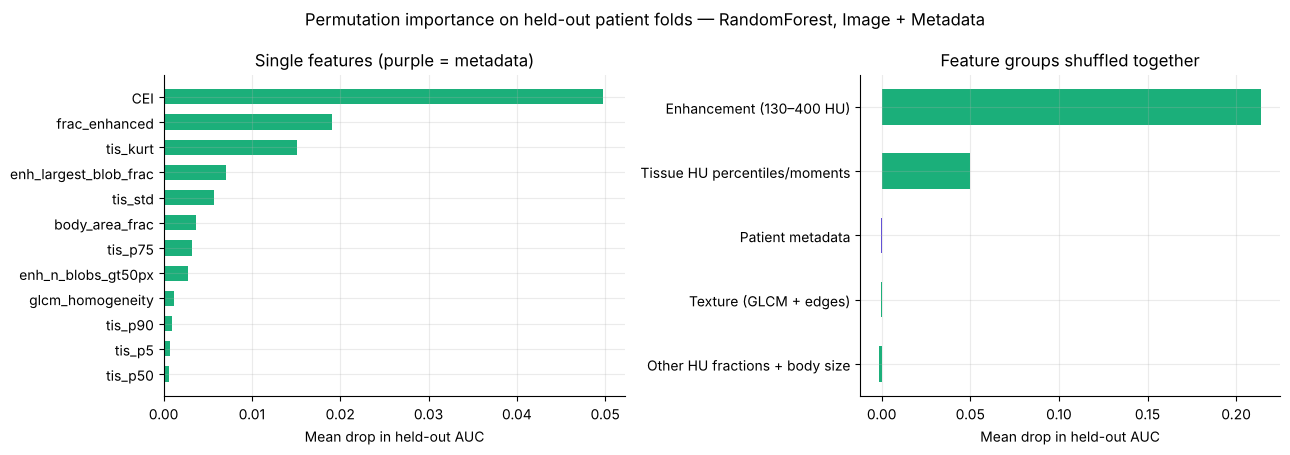

,mean AUC drop
Other HU fractions + body size,-0.0014
Texture (GLCM + edges),-0.0004
Patient metadata,-0.0002
Tissue HU percentiles/moments,0.0499
Enhancement (130–400 HU),0.2140


In [36]:
best_comb = best.get('Image + Metadata', ('Image + Metadata', 'LogReg'))[1]
cols = list(X_comb.columns)
FEATURE_GROUPS = {'Enhancement (130–400 HU)': [c for c in cols if c in ('frac_enhanced', 'CEI') or c.startswith('enh_')],
                  'Other HU fractions + body size': [c for c in cols if c.startswith('frac_') and c != 'frac_enhanced'] + [c for c in cols if c == 'body_area_frac'],
                  'Tissue HU percentiles/moments': [c for c in cols if c.startswith('tis_')],
                  'Texture (GLCM + edges)': [c for c in cols if c.startswith('glcm_') or c == 'edge_mean'],
                  'Patient metadata': [c for c in cols if c in X_meta]}
FEATURE_GROUPS = {g: v for g, v in FEATURE_GROUPS.items() if v}
blocks = {**{c: [c] for c in cols}, **{f'[group] {g}': v for g, v in FEATURE_GROUPS.items()}}

def heldout_drop(model, Xte, yte, block, rng, n_rep=5):
    base = roc_auc_score(yte, model.predict_proba(Xte)[:, 1]); drops = []
    for _ in range(n_rep):
        Xp = Xte.copy(); Xp[block] = Xte[block].values[rng.permutation(len(Xte))]   # shuffle rows of the block jointly
        drops.append(base - roc_auc_score(yte, model.predict_proba(Xp)[:, 1]))
    return np.mean(drops)

rng = np.random.default_rng(SEED); rows = []
for r, k, tr, te in cv_splits(X_comb, y, groups, repeats=2):
    if len(set(y[te])) < 2: continue
    m = clone(make_models()[best_comb]).fit(X_comb.iloc[tr], y[tr])
    rows.append({b: heldout_drop(m, X_comb.iloc[te], y[te], v, rng) for b, v in blocks.items()})
imp_all = pd.DataFrame(rows).mean()
imp = imp_all[cols].sort_values(); grp = imp_all[[f'[group] {g}' for g in FEATURE_GROUPS]].sort_values()
grp.index = grp.index.str.replace('[group] ', '', regex=False)
pd.concat([imp, grp]).to_csv(OUT / 'permutation_importance.csv', header=['mean_AUC_drop'])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [1.1, 1]})
top = imp.tail(12)
ax[0].barh(top.index, top.values, color=[C_SET['Metadata only'] if c in X_meta else C_SET['Image only'] for c in top.index], height=.6)
ax[0].set(xlabel='Mean drop in held-out AUC', title='Single features (purple = metadata)')
ax[1].barh(grp.index, grp.values, color=[C_SET['Metadata only'] if g == 'Patient metadata' else C_SET['Image only'] for g in grp.index], height=.55)
ax[1].set(xlabel='Mean drop in held-out AUC', title='Feature groups shuffled together')
fig.suptitle(f'Permutation importance on held-out patient folds — {best_comb}, Image + Metadata')
savefig('09_permutation_importance')
display(grp.round(4).to_frame('mean AUC drop'))

if best_comb == 'LogReg':   # signed weights: direction of effect (fit on all data, for interpretation only)
    lr = clone(make_models()['LogReg']).fit(X_comb, y)
    coef = pd.Series(lr.named_steps['clf'].coef_[0], index=X_comb.columns).sort_values()
    display(coef.round(3).to_frame('standardised coefficient (+ = pushes towards contrast)'))

**8.3b Is each group sufficient on its own?** Permutation importance asks "what breaks if I remove this?". The complementary question is "how far does this group get *alone*?". If several groups each reach a high AUC alone, they carry overlapping information — which explains small permutation importances.

,AUC mean,AUC sd
Patient metadata,0.552,0.123
Other HU fractions + body size,0.622,0.122
Texture (GLCM + edges),0.837,0.065
Tissue HU percentiles/moments,0.890,0.097
Enhancement (130–400 HU),0.932,0.059


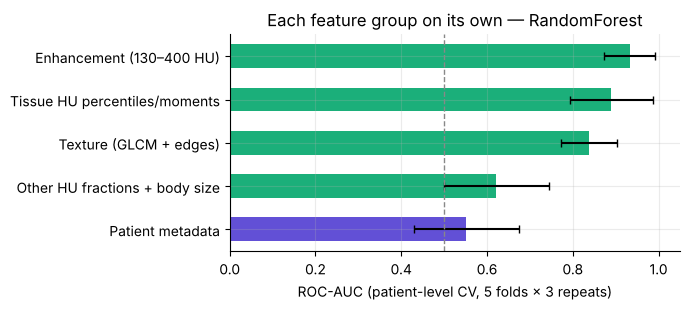

In [37]:
alone = {}
for g, gcols in FEATURE_GROUPS.items():
    sc, _ = evaluate(make_models()[best_comb], X_comb[gcols], y, groups, repeats=3)
    alone[g] = (sc.AUC.mean(), sc.AUC.std())
alone = pd.DataFrame(alone, index=['AUC mean', 'AUC sd']).T.sort_values('AUC mean')
alone.round(3).to_csv(OUT / 'single_group_auc.csv'); display(alone.round(3))
plt.figure(figsize=(7, 3.2))
plt.barh(alone.index, alone['AUC mean'], xerr=alone['AUC sd'], height=.55, capsize=3,
         color=[C_SET['Metadata only'] if g == 'Patient metadata' else C_SET['Image only'] for g in alone.index])
plt.axvline(.5, ls='--', color='#888', lw=1); plt.xlim(0, 1.05); plt.xlabel('ROC-AUC (patient-level CV, 5 folds × 3 repeats)')
plt.title(f'Each feature group on its own — {best_comb}')
savefig('09b_single_group_auc')

**8.4 Visual explanation + label audit.** We paint the pixels that fall in the enhanced-blood band (130–400 HU) on top of the image. For correctly classified slices this shows *where* the evidence is. For the slices the model gets most confidently wrong, it lets a human check whether the **label** might be wrong — the contrast flag came from a header field, not from a radiologist reading the image.

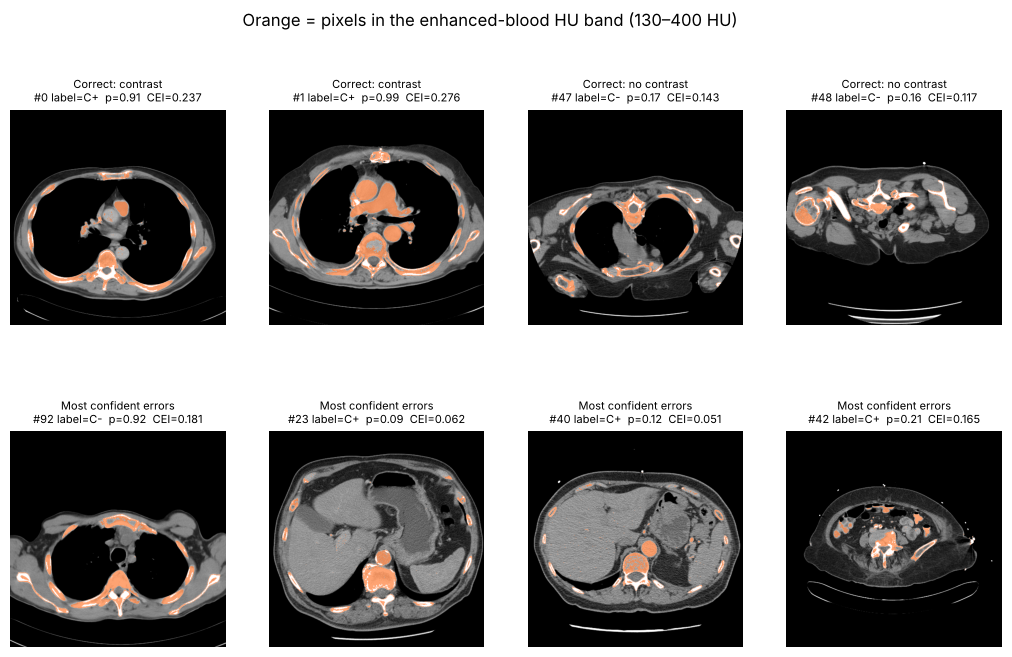

,row,label,prob_contrast,CEI,file,StudyDescription,SeriesDescription,ContrastBolusAgent
0,92,0,0.922,0.1811,ID_0097_AGE_0060_CONTRAST_0_CT.tif,,,
1,23,1,0.086,0.0616,ID_0025_AGE_0074_CONTRAST_1_CT.tif,CT CHEST W/ CONTRAST,HELICAL MODE,
2,40,1,0.120,0.0506,ID_0043_AGE_0069_CONTRAST_1_CT.tif,Outside Read or Comparison BODY CT,PE STUDY ST,100 ML OPTI 350
3,42,1,0.210,0.1646,ID_0045_AGE_0074_CONTRAST_1_CT.tif,CT Abd and Pelvis with cont,ABD/PEL 3.0 B20f,
4,30,1,0.401,0.1433,ID_0032_AGE_0061_CONTRAST_1_CT.tif,,PE-Fast #1,APPLIED
5,43,1,0.410,0.1173,ID_0046_AGE_0072_CONTRAST_1_CT.tif,,,
6,77,0,0.587,0.1676,ID_0081_AGE_0058_CONTRAST_0_CT.tif,PET/CT Sk-Thigh,CT WB 5.0 B31f,
7,2,1,0.415,0.2092,ID_0002_AGE_0074_CONTRAST_1_CT.tif,CT CHEST W/WO CONTRAST,,APPLIED
8,20,1,0.448,0.1443,ID_0022_AGE_0074_CONTRAST_1_CT.tif,CT THORAX WITH AND WI,Smart Prep Series,REDI CAT & 125CC OPTIRAY
9,50,0,0.514,0.1386,ID_0053_AGE_0073_CONTRAST_0_CT.tif,CT LIMITED OR LOCALIZED F/U,HELICAL MODE,


In [38]:
P = oof_prob[('Image + Metadata', best_comb)]
err = np.abs(P - y)
picks = {'Correct: contrast': np.where((y == 1) & (P >= .5))[0], 'Correct: no contrast': np.where((y == 0) & (P < .5))[0],
         'Most confident errors': np.argsort(-err)}
sel = [(t, i) for t, ids in picks.items() for i in (ids[:2] if t != 'Most confident errors' else ids[:4]) if len(ids)]
fig, ax = plt.subplots(2, (len(sel) + 1) // 2, figsize=(3.2 * ((len(sel) + 1) // 2), 7.6), gridspec_kw={'hspace': .22})
for a, (t, i) in zip(ax.ravel(), sel):
    a.imshow(window(HU[i], 40, 400), cmap='gray')
    over = np.zeros((*HU[i].shape, 4)); over[((HU[i] >= 130) & (HU[i] < 400)) & MASK[i]] = [1, .35, 0, .55]
    a.imshow(over); a.axis('off')
    a.set_title(f'{t}\n#{i} label={"C+" if y[i] else "C-"}  p={P[i]:.2f}  CEI={X_img.CEI[i]:.3f}' if 'CEI' in X_img else f'{t}\n#{i}  p={P[i]:.2f}', fontsize=8)
for a in ax.ravel()[len(sel):]: a.axis('off')
fig.suptitle('Orange = pixels in the enhanced-blood HU band (130–400 HU)')
plt.savefig(FIG / '10_explanations_label_audit.png', dpi=150, bbox_inches='tight'); plt.show()
audit_tbl = pd.DataFrame({'row': np.argsort(-err)[:10]}).assign(label=lambda d: y[d.row], prob_contrast=lambda d: P[d.row].round(3))
if 'CEI' in X_img: audit_tbl['CEI'] = X_img.CEI.values[audit_tbl.row].round(4)
if name_col: audit_tbl['file'] = df[name_col].values[audit_tbl.row]
for t in ['StudyDescription', 'SeriesDescription', 'ContrastBolusAgent']:   # shown for HUMAN review only — never used as features
    if t in hdr: audit_tbl[t] = hdr[t].fillna('').values[audit_tbl.row]
audit_tbl.to_csv(OUT / 'label_audit_top_errors.csv', index=False); display(audit_tbl)

**8.4b Error-analysis refinement: bone-suppressed enhancement.**

*Why:* the label audit above showed two systematic failure modes. (1) Spongy bone (vertebrae, ribs) falls in the 130–400 HU band, so bone is painted "enhanced" in **every** image. (2) Upper-abdomen slices with a brightly enhanced aorta were still called "no contrast" because the large liver/spleen dilutes the enhanced *fraction*.

*Fix (CT physics, no new labels):* mark bone as everything ≥ 400 HU, grow it by 3 pixels and fill its interior (so the marrow inside cortical bone is included), then remove that region from the enhancement band. Four features result: bone-free enhanced fraction, bone-free CEI, the **area in mm²** of the largest bone-free enhanced region (the aorta/heart — an absolute size, so organ dilution does not matter), and the bone fraction itself.

> ⚠️ **Honesty note for the report:** this refinement was designed *after* looking at errors on this same dataset. There is no separate test set, so any gain here is optimistic and must be reported as a post-hoc, hypothesis-generating result.

Threshold-free AUC of single raw features (no model, no fitting):


,AUC
CEI,0.935
CEI_nobone,0.945
frac_enhanced,0.913
frac_enh_nobone,0.948
enh_nobone_largest_mm2,0.884


Original 25 HU features (LogReg)           AUC 0.938 ± 0.053 | F1 0.885 | BalAcc 0.894
4 bone-suppressed features (LogReg)        AUC 0.950 ± 0.046 | F1 0.870 | BalAcc 0.884
25 + 4 features (LogReg)                   AUC 0.940 ± 0.052 | F1 0.881 | BalAcc 0.891

4 bone-suppressed vs original on identical folds: mean ΔAUC = +0.011, better in 50%, worse in 40% of folds


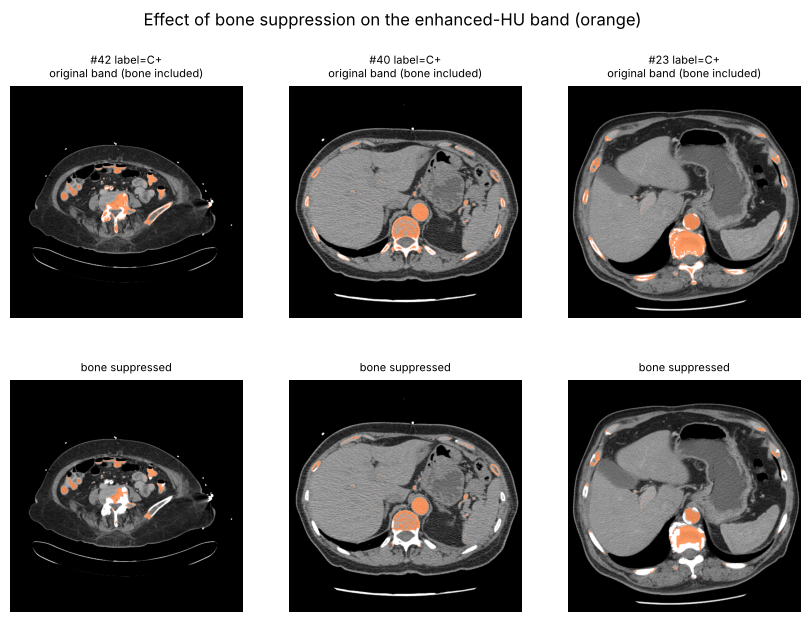

In [39]:
spacing = np.array([float(pydicom.dcmread(p, stop_before_pixels=True).PixelSpacing[0]) for p in df['dcm_path']])   # mm per pixel

def bone_suppressed(hu, m, mm_per_px):
    bone = (hu >= 400) & m
    bone = ndimage.binary_fill_holes(cv2.dilate(bone.astype(np.uint8), np.ones((7, 7), np.uint8)).astype(bool))
    enh = (hu >= 130) & (hu < 400) & m
    soft = (hu >= -30) & (hu < 130) & m
    enh_nb = enh & ~bone
    e = cv2.morphologyEx(enh_nb.astype(np.uint8), cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n, _, st, _ = cv2.connectedComponentsWithStats(e)
    largest_px = st[1:, cv2.CC_STAT_AREA].max() if n > 1 else 0
    return ({'frac_enh_nobone': enh_nb.sum() / m.sum(), 'CEI_nobone': enh_nb.sum() / (soft.sum() + enh_nb.sum() + 1e-6),
             'enh_nobone_largest_mm2': largest_px * mm_per_px ** 2, 'bone_frac': bone.sum() / m.sum()}, enh & bone, enh_nb)

X_bone = pd.DataFrame([bone_suppressed(h, m, sp)[0] for h, m, sp in zip(HU, MASK, spacing)])
print('Threshold-free AUC of single raw features (no model, no fitting):')
display(pd.Series({c: roc_auc_score(y, X_bone[c] if c in X_bone else X_img[c]) for c in ['CEI', 'CEI_nobone', 'frac_enhanced', 'frac_enh_nobone', 'enh_nobone_largest_mm2']}).round(3).to_frame('AUC'))

bone_scores, bone_oof = evaluate(make_models()['LogReg'], X_bone, y, groups)
v1b_scores, _ = evaluate(make_models()['LogReg'], pd.concat([X_img, X_bone], axis=1), y, groups)
ref = fold_scores[best['Image only']]
for name, sc in [(f"Original 25 HU features ({best['Image only'][1]})", ref), ('4 bone-suppressed features (LogReg)', bone_scores), ('25 + 4 features (LogReg)', v1b_scores)]:
    print(f'{name:42s} AUC {sc.AUC.mean():.3f} ± {sc.AUC.std():.3f} | F1 {sc.F1.mean():.3f} | BalAcc {sc.BalancedAcc.mean():.3f}')
d = bone_scores.AUC.values - ref.AUC.values
print(f'\n4 bone-suppressed vs original on identical folds: mean ΔAUC = {np.nanmean(d):+.3f}, better in {np.mean(d > 0):.0%}, worse in {np.mean(d < 0):.0%} of folds')

# Before/after on the slices the original model got most confidently wrong
show = np.argsort(-np.abs(oof_prob[best['Image only']] - y))[:3]
fig, ax = plt.subplots(2, len(show), figsize=(3.4 * len(show), 7))
for j, i in enumerate(show):
    _, enh_bone, enh_nb = bone_suppressed(HU[i], MASK[i], spacing[i])
    for r, (mask_on, title) in enumerate([(enh_nb | enh_bone, 'original band (bone included)'), (enh_nb, 'bone suppressed')]):
        a = ax[r, j]; a.imshow(window(HU[i], 40, 400), cmap='gray')
        over = np.zeros((*HU[i].shape, 4)); over[mask_on] = [1, .35, 0, .6]; a.imshow(over); a.axis('off')
        a.set_title(f'#{i} label={"C+" if y[i] else "C-"}\n{title}' if r == 0 else title, fontsize=8)
fig.suptitle('Effect of bone suppression on the enhanced-HU band (orange)')
plt.savefig(FIG / '12_bone_suppression.png', dpi=150, bbox_inches='tight'); plt.show()

**Known weakness, visible above:** ribs are removed well, but a **vertebral body's interior often stays orange**. In a single 2-D slice its cortical rim is not a closed ring, so hole-filling cannot reach the marrow inside. A proper fix needs spine segmentation (future scope). It was deliberately *not* tuned further on this dataset, because every extra tweak made after looking at the results makes the estimate more optimistic.

**8.5 Ensemble and the final baseline-vs-proposed comparison.**

*Generic baseline* (what a standard tutorial does): take the 8-bit display image, shrink it to 32×32, flatten the pixels, reduce with PCA, classify with Logistic Regression. No Hounsfield Units, no body mask, no physics. *Metadata baseline*: age/sex only.

*Proposed* adds, step by step: HU physics features → + patient metadata → + nested feature selection & tuning → + a **soft-voting ensemble** (averages the probabilities of LogReg, Random Forest and SVM, so one model's mistakes can be outvoted).

All rows use the same patient-level folds (the nested row uses fewer repeats because it is ~25× more expensive). The last row is the post-hoc refinement from 8.4b, shown separately because it was designed after seeing errors.

,Approach,Type,AUC,BalancedAcc,Sensitivity,Specificity,Precision,F1,Accuracy,Note
0,Metadata only (RandomForest),Baseline,0.554 ± 0.137,0.533 ± 0.112,0.623 ± 0.216,0.444 ± 0.196,0.525 ± 0.106,0.556 ± 0.147,0.532 ± 0.113,age/sex
1,Raw pixels → PCA → LogReg,Baseline,0.762 ± 0.138,0.702 ± 0.105,0.728 ± 0.159,0.677 ± 0.148,0.698 ± 0.119,0.705 ± 0.120,0.703 ± 0.107,"8-bit, no HU, no mask"
2,HU features (LogReg),Proposed,0.938 ± 0.053,0.894 ± 0.064,0.848 ± 0.117,0.939 ± 0.080,0.939 ± 0.076,0.885 ± 0.074,0.893 ± 0.064,
3,HU features + metadata (RandomForest),Proposed,0.937 ± 0.056,0.874 ± 0.071,0.833 ± 0.130,0.915 ± 0.100,0.920 ± 0.091,0.865 ± 0.084,0.874 ± 0.071,
4,+ nested selection & tuning (LogReg),Proposed,0.922 ± 0.059,0.843 ± 0.068,0.792 ± 0.106,0.894 ± 0.121,0.899 ± 0.107,0.834 ± 0.067,0.844 ± 0.067,3 repeats
5,+ soft-voting ensemble,Proposed,0.938 ± 0.056,0.883 ± 0.080,0.816 ± 0.144,0.949 ± 0.062,0.943 ± 0.069,0.868 ± 0.102,0.883 ± 0.081,LogReg + RF + SVM
6,"Bone-suppressed enhancement, 4 features (LogReg)",Post-hoc,0.950 ± 0.046,0.884 ± 0.079,0.820 ± 0.136,0.947 ± 0.065,0.941 ± 0.074,0.870 ± 0.097,0.884 ± 0.078,designed after error analysis


Proposed (HU + metadata) vs raw-pixel baseline on identical folds: mean ΔAUC = +0.175, better in 94% of folds


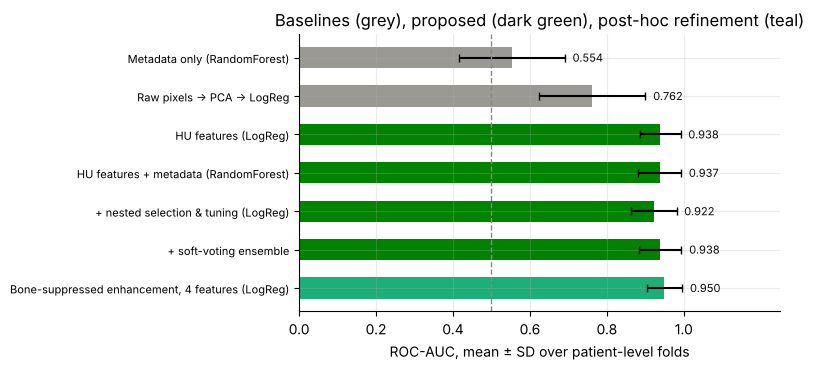

In [40]:
X_raw = pd.DataFrame(np.stack([cv2.resize(window(h, 40, 400), (32, 32), interpolation=cv2.INTER_AREA).ravel() / 255 for h in HU]))
X_raw.columns = [f'px{i}' for i in range(X_raw.shape[1])]
raw_baseline = Pipeline([('scale', StandardScaler()), ('pca', PCA(n_components=min(20, len(y) // 3), random_state=SEED)),
                         ('clf', LogisticRegression(max_iter=5000, class_weight='balanced'))])
raw_scores, raw_oof = evaluate(raw_baseline, X_raw, y, groups)

ensemble = VotingClassifier(list(make_models().items()), voting='soft')
ens_scores, ens_oof = evaluate(ensemble, X_comb, y, groups)

SHOW = ['AUC', 'BalancedAcc', 'Recall', 'Specificity', 'Precision', 'F1', 'Accuracy']
def row(name, kind, sc, note=''):
    return {'Approach': name, 'Type': kind, **{m: f'{sc[m].mean():.3f} ± {sc[m].std():.3f}' for m in SHOW}, 'Note': note}
best_nested = max(nested, key=lambda k: nested[k].AUC.mean())
rows, auc_bars = [], []
for name, kind, sc, note in [
        (f"Metadata only ({best['Metadata only'][1]})" if 'Metadata only' in best else None, 'Baseline', fold_scores.get(best.get('Metadata only')), 'age/sex'),
        ('Raw pixels → PCA → LogReg', 'Baseline', raw_scores, '8-bit, no HU, no mask'),
        (f"HU features ({best['Image only'][1]})", 'Proposed', fold_scores[best['Image only']], ''),
        (f"HU features + metadata ({best['Image + Metadata'][1]})", 'Proposed', fold_scores[best['Image + Metadata']], ''),
        (f'+ nested selection & tuning ({best_nested})', 'Proposed', nested[best_nested], f'{NESTED_REPEATS} repeats'),
        ('+ soft-voting ensemble', 'Proposed', ens_scores, 'LogReg + RF + SVM'),
        ('Bone-suppressed enhancement, 4 features (LogReg)', 'Post-hoc', bone_scores, 'designed after error analysis')]:
    if name is None: continue
    rows.append(row(name, kind, sc, note)); auc_bars.append((name, kind, sc.AUC.mean(), sc.AUC.std()))
final_tbl = pd.DataFrame(rows).rename(columns={'Recall': 'Sensitivity'})
final_tbl.to_csv(OUT / 'baseline_vs_proposed.csv', index=False); display(final_tbl)

d = fold_scores[best['Image + Metadata']].AUC.values - raw_scores.AUC.values
print(f'Proposed (HU + metadata) vs raw-pixel baseline on identical folds: mean ΔAUC = {np.nanmean(d):+.3f}, better in {np.mean(d > 0):.0%} of folds')

names, kinds, means, sds = zip(*auc_bars)
plt.figure(figsize=(8, 3.8))
yy = np.arange(len(names))[::-1]
plt.barh(yy, means, xerr=sds, height=.55, capsize=3, color=['#9a9994' if k == 'Baseline' else C_SET['Image only'] if k == 'Post-hoc' else C_SET['Image + Metadata'] for k in kinds])
for yi, m, sd in zip(yy, means, sds): plt.text(m + (sd if sd == sd else 0) + .02, yi, f'{m:.3f}', va='center', fontsize=8, color='#0b0b0b')
plt.yticks(yy, names, fontsize=8); plt.axvline(.5, ls='--', color='#888', lw=1); plt.xlim(0, 1.25); plt.xticks(np.arange(0, 1.01, .2))
plt.xlabel('ROC-AUC, mean ± SD over patient-level folds'); plt.title('Baselines (grey), proposed (dark green), post-hoc refinement (teal)')
savefig('11_baseline_vs_proposed')

## Part 9 — Results summary from *this* run

The cell below gathers the numbers you need for the report into one place and saves `results/run_summary.json`. Write your interpretation from these, in your own words.

In [41]:
best_overall = max(fold_scores, key=lambda k: fold_scores[k]['AUC'].mean())
run = {'n_slices': int(len(y)), 'n_contrast': int(y.sum()), 'n_patients': int(len(np.unique(groups))),
       'patient_level_split': bool(PID_COL), 'metadata_features': list(X_meta.columns), 'n_image_features': int(X_img.shape[1]),
       'excluded_as_leaky': sorted(LEAKY),
       'best_per_feature_set': {fs: {'model': k[1], 'AUC_mean': round(fold_scores[k].AUC.mean(), 3), 'AUC_sd': round(fold_scores[k].AUC.std(), 3),
                                     'F1_mean': round(fold_scores[k].F1.mean(), 3)} for fs, k in best.items()},
       'best_overall': {'feature_set': best_overall[0], 'model': best_overall[1]},
       'nested_tuned_AUC': {m: round(v.AUC.mean(), 3) for m, v in nested.items()},
       'permutation_test': {'real_AUC': round(real, 3), 'p_value': round(p_val, 4), 'n_permutations': N_PERM},
       'top5_important_features': imp.tail(5)[::-1].round(4).to_dict(),
       'feature_group_importance': grp[::-1].round(4).to_dict(),
       'single_group_AUC': alone['AUC mean'].round(3).to_dict(),
       'raw_pixel_baseline_AUC': round(raw_scores.AUC.mean(), 3), 'ensemble_AUC': round(ens_scores.AUC.mean(), 3),
       'posthoc_bone_suppressed_AUC': round(bone_scores.AUC.mean(), 3), 'posthoc_bone_suppressed_AUC_sd': round(bone_scores.AUC.std(), 3),
       'n_duplicates_removed': int(dup.sum()), 'acquisition_shortcut_AUC': round(acq_scores.AUC.mean(), 3) if X_acq.shape[1] else None,
       'library_versions': versions}
(OUT / 'run_summary.json').write_text(json.dumps(run, indent=2)); print(json.dumps(run, indent=2))
X_img.assign(**X_meta, label=y, group=groups).to_csv(OUT / 'features.csv', index=False)

{
  "n_slices": 94,
  "n_contrast": 47,
  "n_patients": 54,
  "patient_level_split": true,
  "metadata_features": [
    "age",
    "sex_male"
  ],
  "n_image_features": 25,
  "excluded_as_leaky": [
    "Contrast",
    "ContrastTag",
    "dcm_CodeMeaning",
    "dcm_ContrastBolusAgent",
    "dcm_ContrastBolusIngredientConcentration",
    "dcm_ContrastBolusRoute",
    "dcm_ContrastBolusVolume",
    "dcm_ContrastFlowDuration",
    "dcm_ContrastFlowRate",
    "dcm_PerformedProcedureStepDescription",
    "dcm_ProtocolName",
    "dcm_RequestedContrastAgent",
    "dcm_RequestedProcedureDescription",
    "dcm_StudyDescription",
    "dicom_name",
    "raw_input_path",
    "tiff_name"
  ],
  "best_per_feature_set": {
    "Metadata only": {
      "model": "RandomForest",
      "AUC_mean": 0.554,
      "AUC_sd": 0.137,
      "F1_mean": 0.556
    },
    "Image only": {
      "model": "LogReg",
      "AUC_mean": 0.938,
      "AUC_sd": 0.053,
      "F1_mean": 0.885
    },
    "Image + Metadata": {
   

### Questions to answer in your own words (report → Results & Discussion)
1. Which feature set won, and by how much? Is the gap larger than the fold-to-fold spread (look at the box plot)?
2. Did the proposed HU features beat the raw-pixel baseline? Did tuning or the ensemble add anything beyond the plain combined model?
3. Did metadata add anything on top of the image? If not — why would age carry little information about whether contrast was injected?
4. Do the top features make physical sense (enhanced-band fraction, CEI, high HU percentiles)? If a body-size or texture feature dominates instead, what might that mean?
5. Is the permutation p-value small? What does that rule out, and what does it *not* prove?
6. Look at the most confident errors: does the image look enhanced while the label says no contrast (or vice versa)? That is evidence about **label quality**, not just model quality.

### If the labels are missing or unusable
If Part 1 shows no reliable binary label, do **not** create one from guesses. Feasible alternatives using only what exists: (a) **age-group classification** (e.g. < 60 vs ≥ 60) from image features, with the same patient-level CV; (b) **unsupervised analysis** — cluster the HU features (k-means / PCA) and check whether clusters line up with any available field. State the change of task explicitly in the report.